# Importare bibloteci necesare:


In [ ]:
from __future__ import annotations  # Necesar pentru a folosi tipul clasei în definiția ei
from typing import Optional, Dict, Callable
from pathlib import Path
from copy import deepcopy
from collections import Counter
from datetime import datetime

import pandas as pd  # Pentru a citi si afisa datele
import numpy as np
from graphviz import Digraph, Source  # Pentru a vizualiza arborele de decizie
from IPython.display import display as idisplay  # Pentru a afisa arborele de decizie direct în celulă
from matplotlib import pyplot as plt
import seaborn as sns
from tqdm import tqdm
from scipy.stats import chi2_contingency

from sklearn.impute import SimpleImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn import preprocessing
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import f1_score, recall_score, precision_score, accuracy_score

from google.colab import data_table

# Citire date:


In [ ]:
bycicle_train_set = pd.read_csv("train_split.csv")
bycicle_test_set = pd.read_csv("eval_split.csv")
cars_train_set = pd.read_csv("train_cars_listings.csv")
cars_test_set = pd.read_csv("val_cars_listings.csv")

display(bycicle_train_set)
display(bycicle_test_set)

/tmp/ipython-input-1114876573.py:3: DtypeWarning: Columns (31) have mixed types. Specify dtype option on import or set low_memory=False.
  cars_train_set = pd.read_csv("train_cars_listings.csv")


,data_ora,sezon,sarbatoare,zi_lucratoare,vreme,temperatura,temperatura_resimtita,umiditate,viteza_vant,ocazionali,inregistrati,total
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0000,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0000,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0000,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0000,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0000,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...
6873,2012-12-12 19:00:00,4,0,1,2,12.30,14.395,56,15.0013,18,384,402
6874,2012-12-12 20:00:00,4,0,1,1,12.30,14.395,52,19.0012,25,243,268
6875,2012-12-12 21:00:00,4,0,1,2,12.30,14.395,52,16.9979,16,186,202
6876,2012-12-12 22:00:00,4,0,1,2,12.30,14.395,52,15.0013,4,118,122


,data_ora,sezon,sarbatoare,zi_lucratoare,vreme,temperatura,temperatura_resimtita,umiditate,viteza_vant,ocazionali,inregistrati,total
0,2011-01-13 00:00:00,1,0,1,1,5.74,6.060,59,19.0012,1,6,7
1,2011-01-13 01:00:00,1,0,1,1,5.74,6.060,50,19.0012,0,2,2
2,2011-01-13 02:00:00,1,0,1,1,5.74,6.060,50,23.9994,0,2,2
3,2011-01-13 03:00:00,1,0,1,1,5.74,6.060,50,22.0028,0,3,3
4,2011-01-13 04:00:00,1,0,1,1,5.74,6.060,50,16.9979,0,4,4
...,...,...,...,...,...,...,...,...,...,...,...,...
4003,2012-12-19 19:00:00,4,0,1,1,15.58,19.695,50,26.0027,7,329,336
4004,2012-12-19 20:00:00,4,0,1,1,14.76,17.425,57,15.0013,10,231,241
4005,2012-12-19 21:00:00,4,0,1,1,13.94,15.910,61,15.0013,4,164,168
4006,2012-12-19 22:00:00,4,0,1,1,13.94,17.425,61,6.0032,12,117,129


# Setul de date "Biciclete":


## Explorarea și Vizualizarea datelor:


This is for train data:


,data_ora,sezon,sarbatoare,zi_lucratoare,vreme,temperatura,temperatura_resimtita,umiditate,viteza_vant,ocazionali,inregistrati,total
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0000,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0000,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0000,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0000,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0000,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...
6873,2012-12-12 19:00:00,4,0,1,2,12.30,14.395,56,15.0013,18,384,402
6874,2012-12-12 20:00:00,4,0,1,1,12.30,14.395,52,19.0012,25,243,268
6875,2012-12-12 21:00:00,4,0,1,2,12.30,14.395,52,16.9979,16,186,202
6876,2012-12-12 22:00:00,4,0,1,2,12.30,14.395,52,15.0013,4,118,122


This is numerical data:


,sezon,sarbatoare,zi_lucratoare,vreme,temperatura,temperatura_resimtita,umiditate,viteza_vant,ocazionali,inregistrati,total
count,6878.000000,6878.000000,6878.000000,6878.000000,6878.000000,6878.000000,6878.000000,6878.000000,6878.000000,6878.000000,6878.000000
mean,2.505670,0.031259,0.676069,1.418436,20.077839,23.505789,61.990259,12.576206,35.356208,153.511050,188.867258
std,1.116669,0.174030,0.468008,0.642373,8.168544,8.869723,19.827335,8.248823,49.064414,150.508752,179.669118
min,1.000000,0.000000,0.000000,1.000000,0.820000,0.760000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,0.000000,0.000000,1.000000,13.120000,15.910000,46.000000,7.001500,4.000000,35.000000,41.000000
50%,3.000000,0.000000,1.000000,1.000000,19.680000,23.485000,62.000000,11.001400,16.000000,115.000000,141.000000
75%,4.000000,0.000000,1.000000,2.000000,27.060000,31.060000,78.000000,16.997900,48.000000,220.000000,282.000000
max,4.000000,1.000000,1.000000,4.000000,41.000000,45.455000,100.000000,56.996900,362.000000,886.000000,977.000000



This is categorical data:


,data_ora
count,6878
unique,6878
top,2012-12-12 23:00:00
freq,1


Echilibru clase:


/tmp/ipython-input-1011301959.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  graph.set_xticklabels(graph.get_xticklabels(), rotation=40, ha="right")


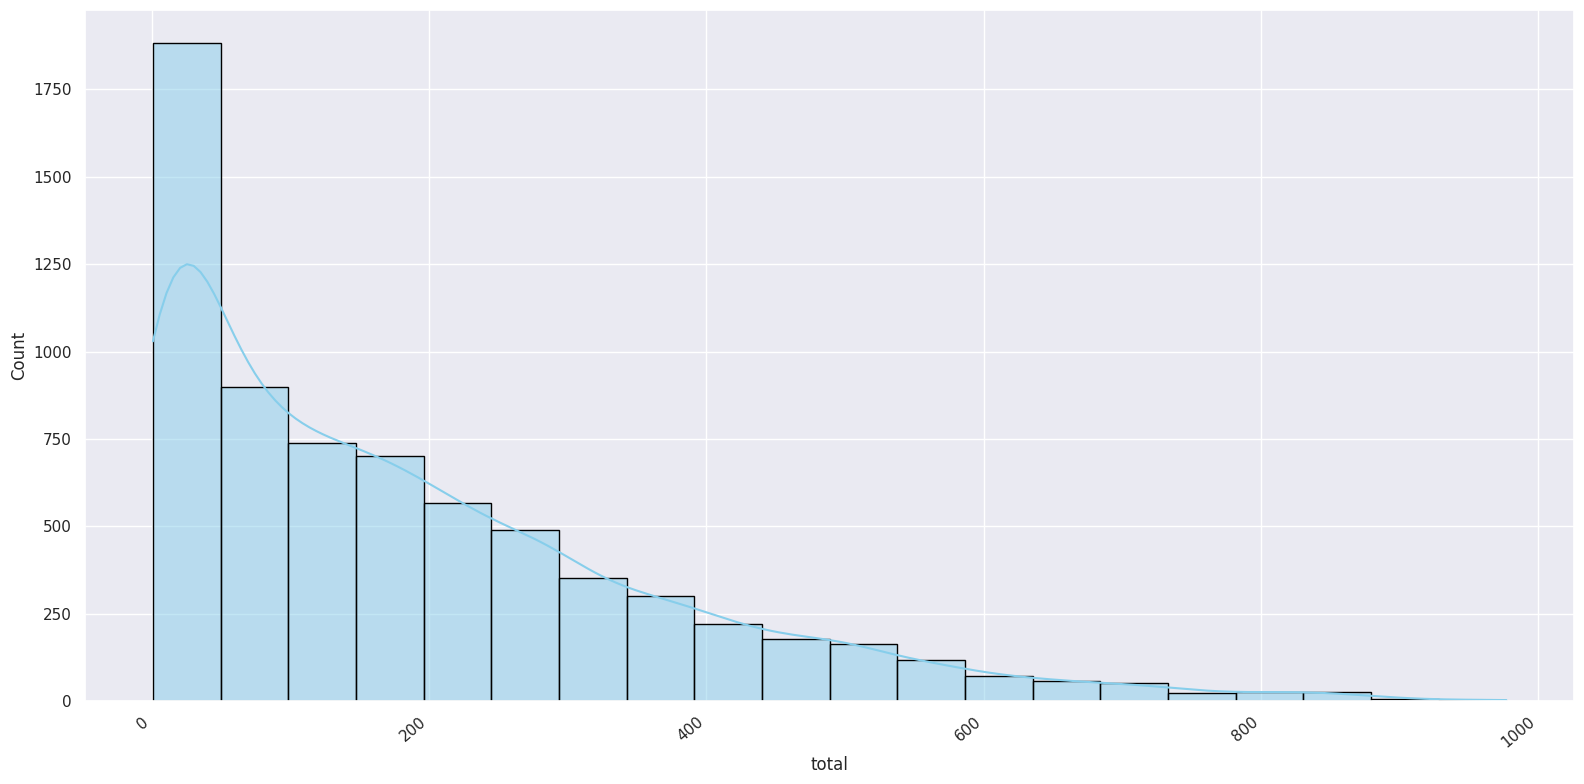

,sezon,sarbatoare,zi_lucratoare,vreme,temperatura,temperatura_resimtita,umiditate,viteza_vant,ocazionali,inregistrati,total,an,luna,zi,ora,minut,secunda
count,6878.000000,6878.000000,6878.000000,6878.000000,6878.000000,6878.000000,6878.000000,6878.000000,6878.000000,6878.000000,6878.000000,6878.000000,6878.000000,6878.000000,6878.000000,6878.0,6878.0
mean,2.505670,0.031259,0.676069,1.418436,20.077839,23.505789,61.990259,12.576206,35.356208,153.511050,188.867258,2011.501454,6.518028,6.494911,11.540855,0.0,0.0
std,1.116669,0.174030,0.468008,0.642373,8.168544,8.869723,19.827335,8.248823,49.064414,150.508752,179.669118,0.500034,3.446326,3.451218,6.915031,0.0,0.0
min,1.000000,0.000000,0.000000,1.000000,0.820000,0.760000,0.000000,0.000000,0.000000,0.000000,1.000000,2011.000000,1.000000,1.000000,0.000000,0.0,0.0
25%,2.000000,0.000000,0.000000,1.000000,13.120000,15.910000,46.000000,7.001500,4.000000,35.000000,41.000000,2011.000000,4.000000,3.000000,6.000000,0.0,0.0
50%,3.000000,0.000000,1.000000,1.000000,19.680000,23.485000,62.000000,11.001400,16.000000,115.000000,141.000000,2012.000000,7.000000,6.000000,12.000000,0.0,0.0
75%,4.000000,0.000000,1.000000,2.000000,27.060000,31.060000,78.000000,16.997900,48.000000,220.000000,282.000000,2012.000000,10.000000,9.000000,18.000000,0.0,0.0
max,4.000000,1.000000,1.000000,4.000000,41.000000,45.455000,100.000000,56.996900,362.000000,886.000000,977.000000,2012.000000,12.000000,12.000000,23.000000,0.0,0.0


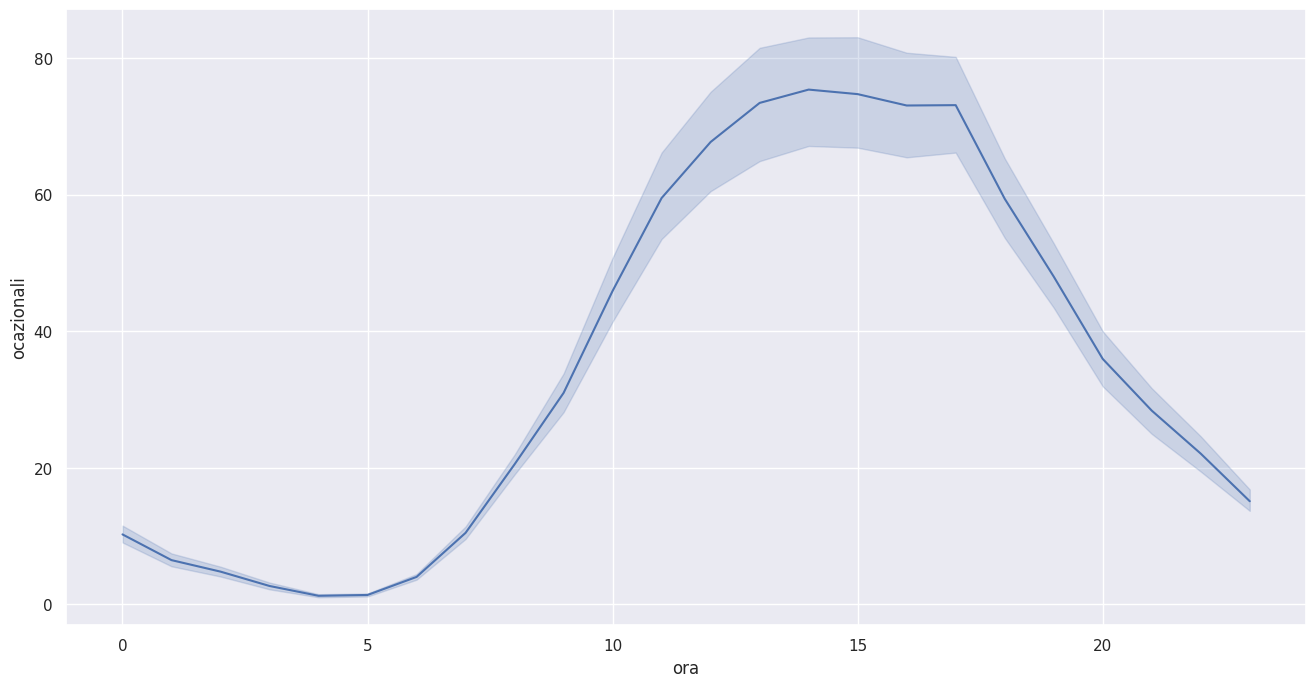

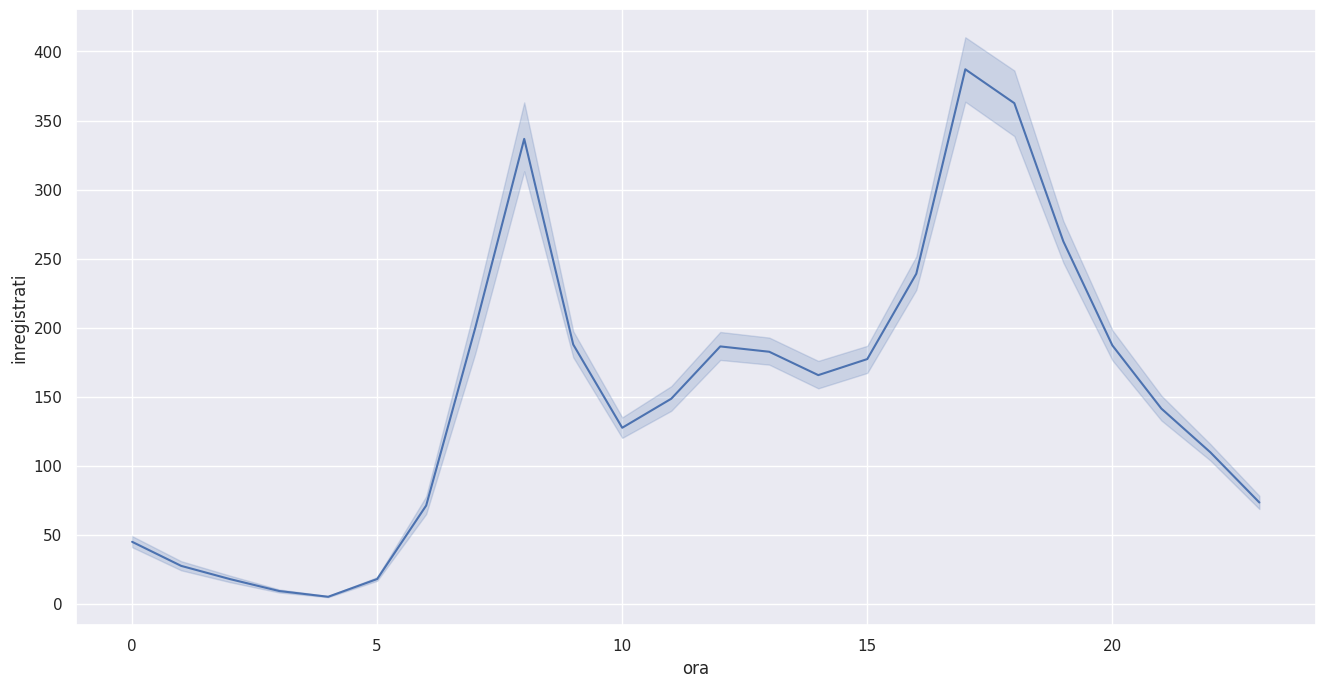

Missing data with signs other than NaN:


,sezon,sarbatoare,zi_lucratoare,vreme,temperatura,temperatura_resimtita,umiditate,viteza_vant,ocazionali,inregistrati,total,an,luna,zi,ora


Corelatie intre coloane:


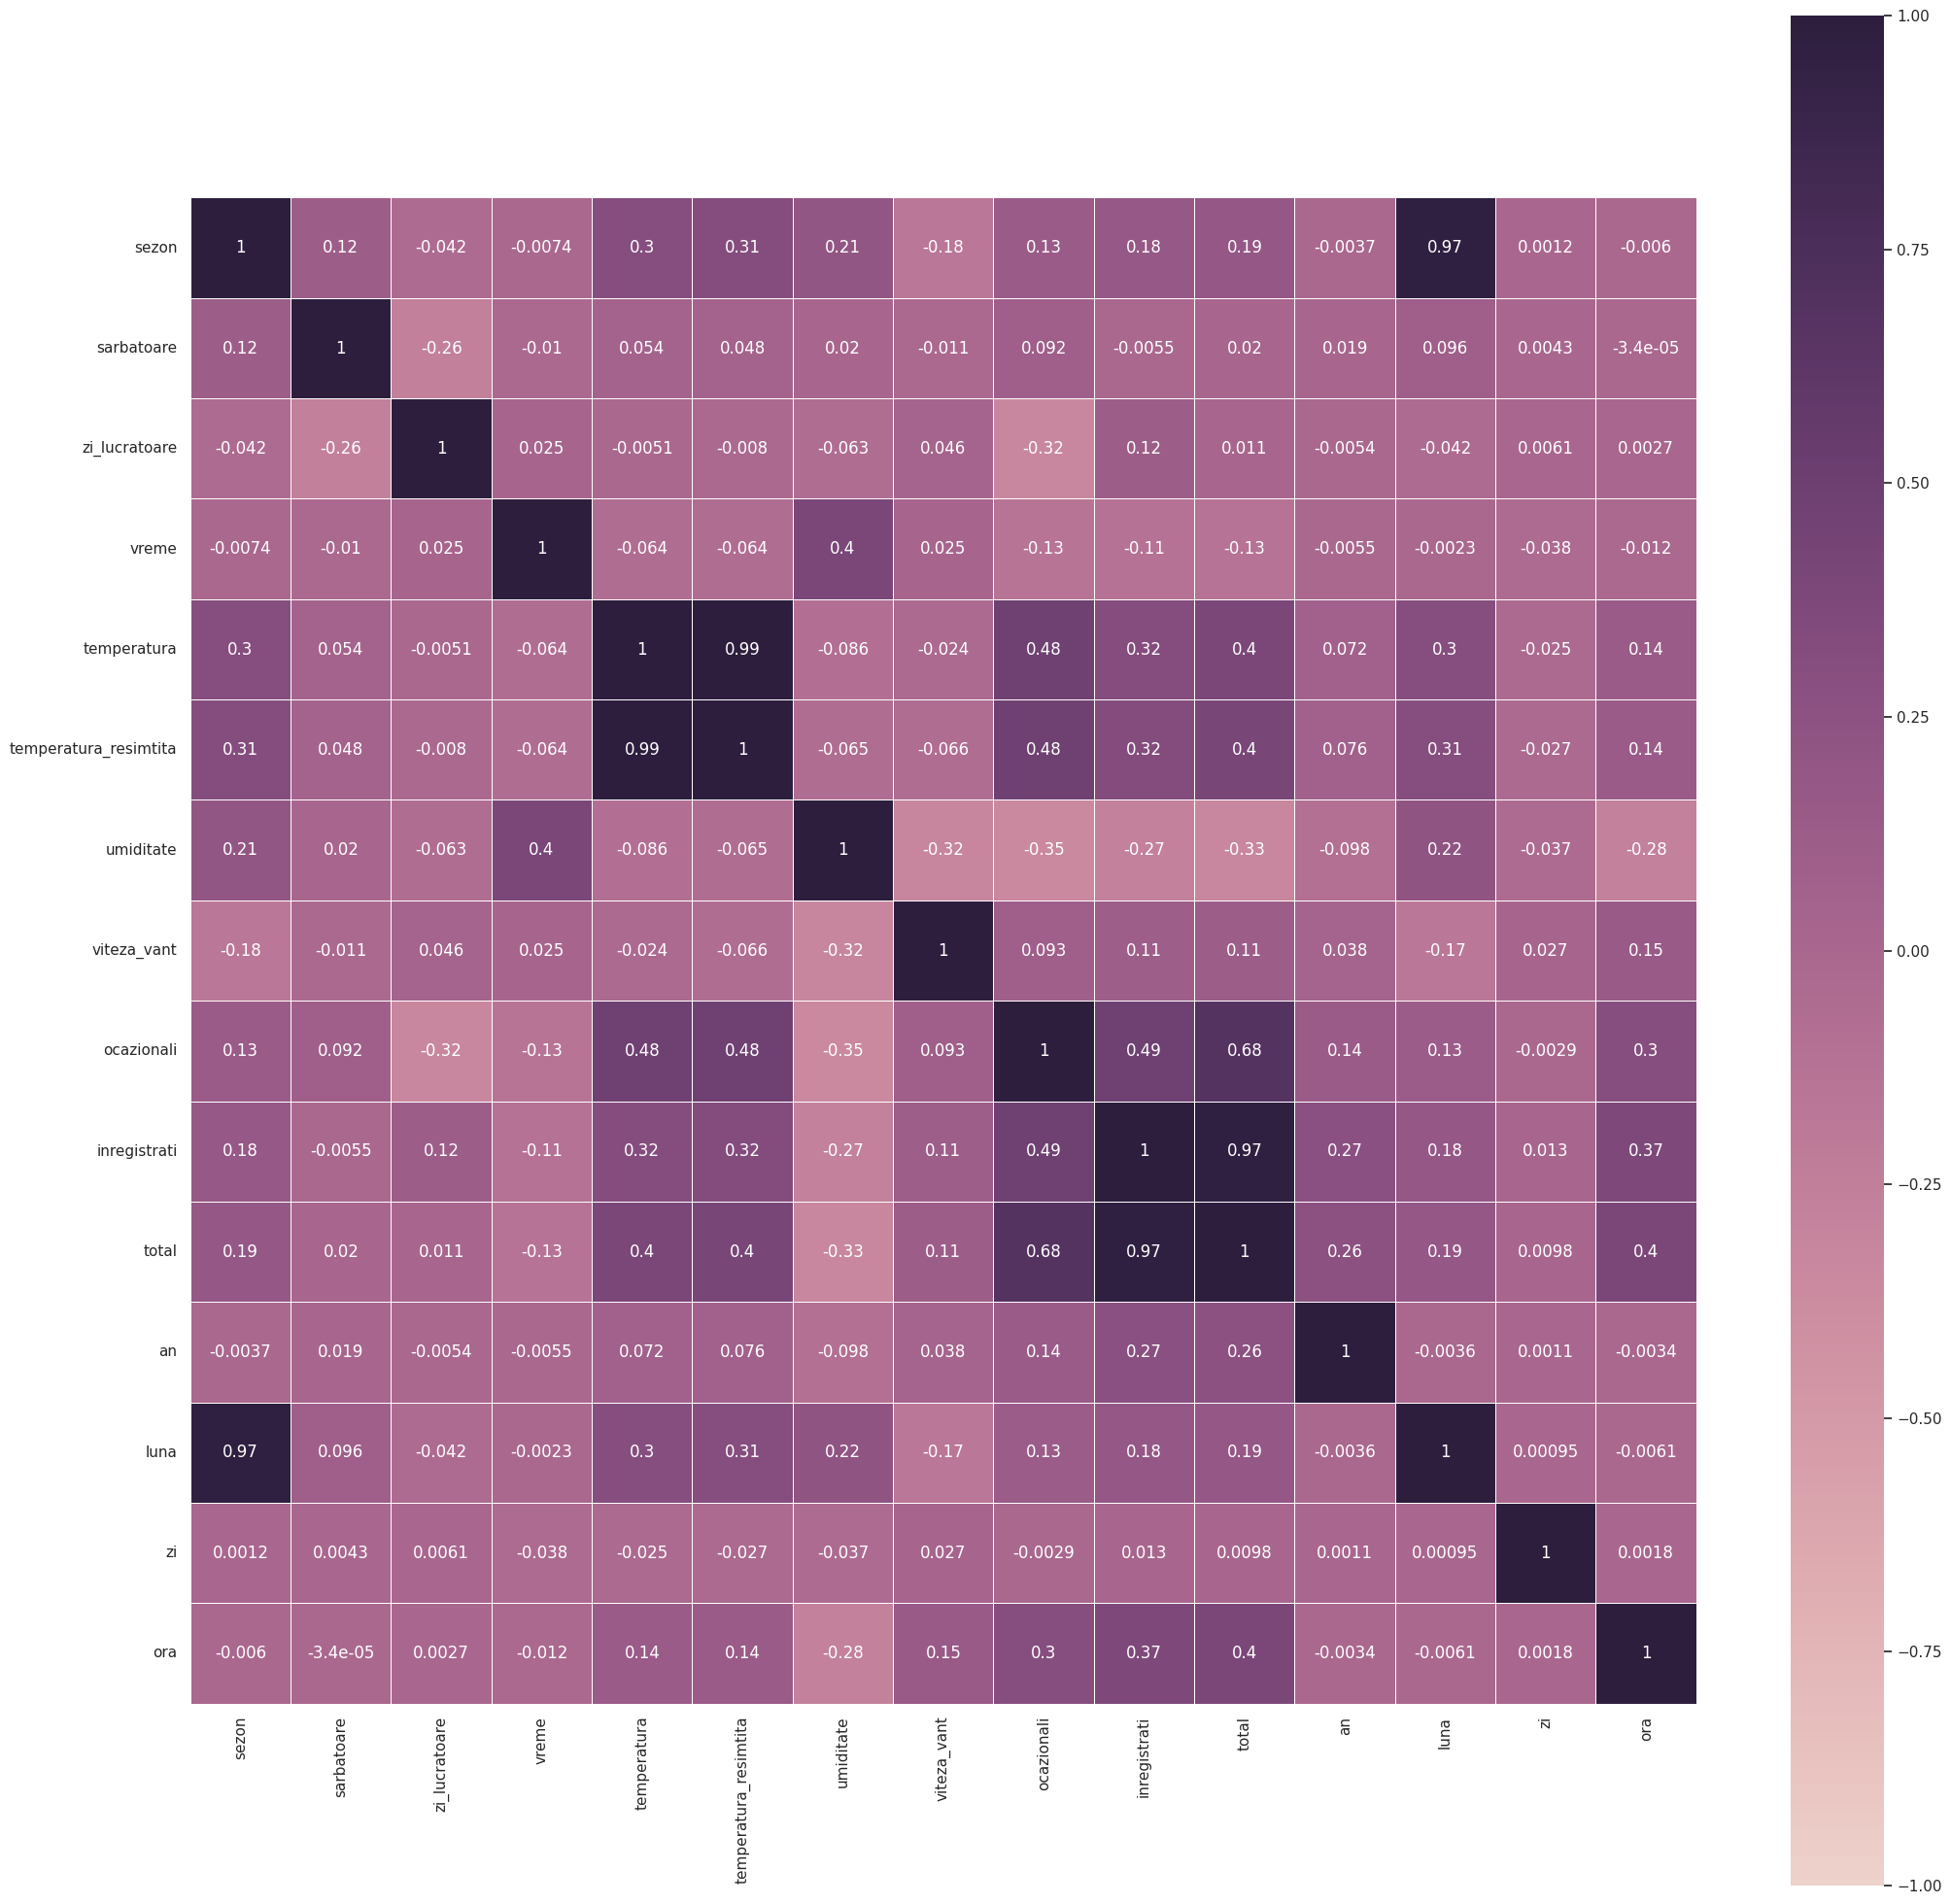

This is for test data:


,data_ora,sezon,sarbatoare,zi_lucratoare,vreme,temperatura,temperatura_resimtita,umiditate,viteza_vant,ocazionali,inregistrati,total
0,2011-01-13 00:00:00,1,0,1,1,5.74,6.060,59,19.0012,1,6,7
1,2011-01-13 01:00:00,1,0,1,1,5.74,6.060,50,19.0012,0,2,2
2,2011-01-13 02:00:00,1,0,1,1,5.74,6.060,50,23.9994,0,2,2
3,2011-01-13 03:00:00,1,0,1,1,5.74,6.060,50,22.0028,0,3,3
4,2011-01-13 04:00:00,1,0,1,1,5.74,6.060,50,16.9979,0,4,4
...,...,...,...,...,...,...,...,...,...,...,...,...
4003,2012-12-19 19:00:00,4,0,1,1,15.58,19.695,50,26.0027,7,329,336
4004,2012-12-19 20:00:00,4,0,1,1,14.76,17.425,57,15.0013,10,231,241
4005,2012-12-19 21:00:00,4,0,1,1,13.94,15.910,61,15.0013,4,164,168
4006,2012-12-19 22:00:00,4,0,1,1,13.94,17.425,61,6.0032,12,117,129


This is numerical data:


,sezon,sarbatoare,zi_lucratoare,vreme,temperatura,temperatura_resimtita,umiditate,viteza_vant,ocazionali,inregistrati,total
count,4008.000000,4008.000000,4008.000000,4008.000000,4008.000000,4008.000000,4008.000000,4008.000000,4008.000000,4008.000000,4008.000000
mean,2.508234,0.023952,0.689122,1.418413,20.493453,23.911285,61.708333,13.182404,37.164421,159.054890,196.219311
std,1.115462,0.152919,0.462911,0.618999,7.091509,7.744107,18.203451,8.004361,51.447960,151.899624,183.578148
min,1.000000,0.000000,0.000000,1.000000,4.100000,5.305000,8.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,0.000000,0.000000,1.000000,14.760000,17.425000,48.000000,7.001500,4.000000,37.750000,45.000000
50%,3.000000,0.000000,1.000000,1.000000,21.320000,25.000000,62.000000,12.998000,18.000000,122.000000,151.000000
75%,4.000000,0.000000,1.000000,2.000000,26.240000,30.305000,76.000000,16.997900,49.000000,226.000000,288.000000
max,4.000000,1.000000,1.000000,3.000000,38.540000,43.940000,100.000000,51.998700,367.000000,839.000000,943.000000



This is categorical data:


,data_ora
count,4008
unique,4008
top,2012-12-19 23:00:00
freq,1


Echilibru clase:


/tmp/ipython-input-1011301959.py:68: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  graph.set_xticklabels(graph.get_xticklabels(), rotation=40, ha="right")


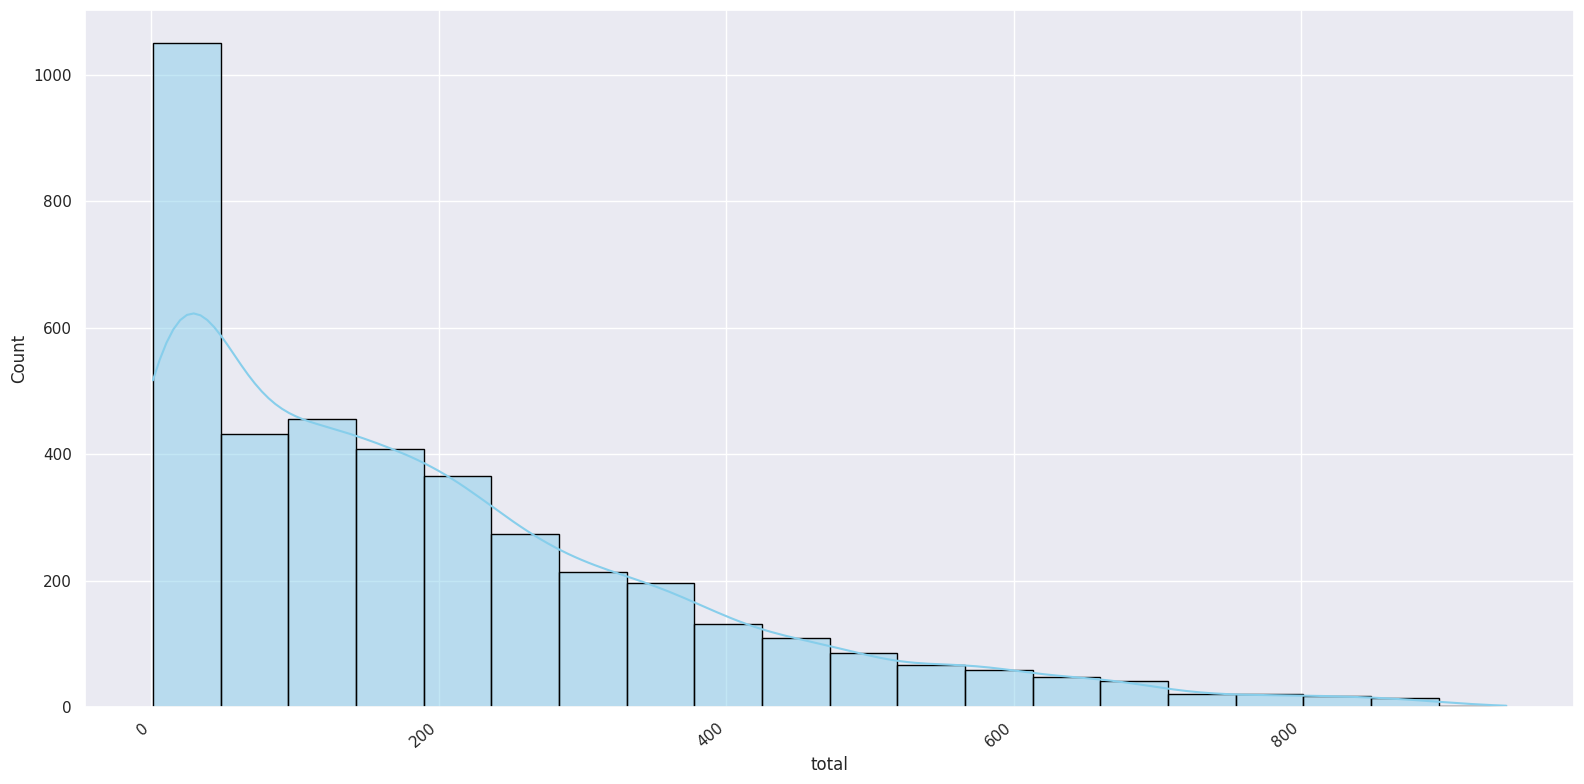

,sezon,sarbatoare,zi_lucratoare,vreme,temperatura,temperatura_resimtita,umiditate,viteza_vant,ocazionali,inregistrati,total,an,luna,zi,ora,minut,secunda
count,4008.000000,4008.000000,4008.000000,4008.000000,4008.000000,4008.000000,4008.000000,4008.000000,4008.000000,4008.000000,4008.000000,4008.000000,4008.000000,4008.000000,4008.000000,4008.0,4008.0
mean,2.508234,0.023952,0.689122,1.418413,20.493453,23.911285,61.708333,13.182404,37.164421,159.054890,196.219311,2011.502745,6.527445,15.994760,11.542914,0.0,0.0
std,1.115462,0.152919,0.462911,0.618999,7.091509,7.744107,18.203451,8.004361,51.447960,151.899624,183.578148,0.500055,3.441441,2.000056,6.918085,0.0,0.0
min,1.000000,0.000000,0.000000,1.000000,4.100000,5.305000,8.000000,0.000000,0.000000,0.000000,1.000000,2011.000000,1.000000,13.000000,0.000000,0.0,0.0
25%,2.000000,0.000000,0.000000,1.000000,14.760000,17.425000,48.000000,7.001500,4.000000,37.750000,45.000000,2011.000000,4.000000,14.000000,6.000000,0.0,0.0
50%,3.000000,0.000000,1.000000,1.000000,21.320000,25.000000,62.000000,12.998000,18.000000,122.000000,151.000000,2012.000000,7.000000,16.000000,12.000000,0.0,0.0
75%,4.000000,0.000000,1.000000,2.000000,26.240000,30.305000,76.000000,16.997900,49.000000,226.000000,288.000000,2012.000000,10.000000,18.000000,18.000000,0.0,0.0
max,4.000000,1.000000,1.000000,3.000000,38.540000,43.940000,100.000000,51.998700,367.000000,839.000000,943.000000,2012.000000,12.000000,19.000000,23.000000,0.0,0.0


Missing data with signs other than NaN:


,sezon,sarbatoare,zi_lucratoare,vreme,temperatura,temperatura_resimtita,umiditate,viteza_vant,ocazionali,inregistrati,total,an,luna,zi,ora


In [ ]:
print('This is for train data:')
sns.set(rc={'figure.figsize': (16, 8)})
display(bycicle_train_set)

print('This is numerical data:')
display(bycicle_train_set.describe())

print()
print('This is categorical data:')
display(bycicle_train_set.describe(include=[object]))

print('Echilibru clase:')
graph = sns.histplot(bycicle_train_set['total'], bins=20, kde=True, color='skyblue', edgecolor='black')
graph.set_xticklabels(graph.get_xticklabels(), rotation=40, ha="right")
plt.tight_layout()
plt.show()

bycicle_train_set['an'] = bycicle_train_set.apply(lambda row: datetime.strptime(row.data_ora, '%Y-%m-%d %H:%M:%S').year, axis = 1)
bycicle_train_set['luna'] = bycicle_train_set.apply(lambda row: datetime.strptime(row.data_ora, '%Y-%m-%d %H:%M:%S').month, axis = 1)
bycicle_train_set['zi'] = bycicle_train_set.apply(lambda row: datetime.strptime(row.data_ora, '%Y-%m-%d %H:%M:%S').day, axis = 1)
bycicle_train_set['ora'] = bycicle_train_set.apply(lambda row: datetime.strptime(row.data_ora, '%Y-%m-%d %H:%M:%S').hour, axis = 1)
bycicle_train_set['minut'] = bycicle_train_set.apply(lambda row: datetime.strptime(row.data_ora, '%Y-%m-%d %H:%M:%S').minute, axis = 1)
bycicle_train_set['secunda'] = bycicle_train_set.apply(lambda row: datetime.strptime(row.data_ora, '%Y-%m-%d %H:%M:%S').second, axis = 1)
bycicle_train_set = bycicle_train_set.drop('data_ora', axis=1)
display(bycicle_train_set.describe())
bycicle_train_set = bycicle_train_set.drop(['minut', 'secunda'], axis=1)

sns.lineplot(data=bycicle_train_set, x="ora", y="ocazionali")
plt.show()

sns.lineplot(data=bycicle_train_set, x="ora", y="inregistrati")
plt.show()


print('Missing data with signs other than NaN:')
notNumericFilter = bycicle_train_set.apply(lambda x: ~x.astype(str).str.match(r'^[\d.]+$'))
notNumeric = bycicle_train_set[notNumericFilter.any(axis=1)]
display(notNumeric.drop_duplicates())

print('Corelatie intre coloane:')
corr_matrix = bycicle_train_set.corr(method='pearson')
sns.set(rc={'figure.figsize': (25, 25)})
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap=sns.cubehelix_palette(as_cmap=True),
    vmin=-1, vmax=1,
    center=0,
    linewidths=0.5,
    square=True
)
plt.show()


print('This is for test data:')
sns.set(rc={'figure.figsize': (16, 8)})
display(bycicle_test_set)

print('This is numerical data:')
display(bycicle_test_set.describe())

print()
print('This is categorical data:')
display(bycicle_test_set.describe(include=[object]))

print('Echilibru clase:')
graph = sns.histplot(bycicle_test_set['total'], bins=20, kde=True, color='skyblue', edgecolor='black')
graph.set_xticklabels(graph.get_xticklabels(), rotation=40, ha="right")
plt.tight_layout()
plt.show()

bycicle_test_set['an'] = bycicle_test_set.apply(lambda row: datetime.strptime(row.data_ora, '%Y-%m-%d %H:%M:%S').year, axis = 1)
bycicle_test_set['luna'] = bycicle_test_set.apply(lambda row: datetime.strptime(row.data_ora, '%Y-%m-%d %H:%M:%S').month, axis = 1)
bycicle_test_set['zi'] = bycicle_test_set.apply(lambda row: datetime.strptime(row.data_ora, '%Y-%m-%d %H:%M:%S').day, axis = 1)
bycicle_test_set['ora'] = bycicle_test_set.apply(lambda row: datetime.strptime(row.data_ora, '%Y-%m-%d %H:%M:%S').hour, axis = 1)
bycicle_test_set['minut'] = bycicle_test_set.apply(lambda row: datetime.strptime(row.data_ora, '%Y-%m-%d %H:%M:%S').minute, axis = 1)
bycicle_test_set['secunda'] = bycicle_test_set.apply(lambda row: datetime.strptime(row.data_ora, '%Y-%m-%d %H:%M:%S').second, axis = 1)
bycicle_test_set = bycicle_test_set.drop('data_ora', axis=1)
display(bycicle_test_set.describe())
bycicle_test_set = bycicle_test_set.drop(['minut', 'secunda'], axis=1)

print('Missing data with signs other than NaN:')
notNumericFilter = bycicle_test_set.apply(lambda x: ~x.astype(str).str.match(r'^[\d.]+$'))
notNumeric = bycicle_test_set[notNumericFilter.any(axis=1)]
display(notNumeric.drop_duplicates())

Analiza date individuale:
Index(['sezon', 'sarbatoare', 'zi_lucratoare', 'vreme', 'temperatura',
       'temperatura_resimtita', 'umiditate', 'viteza_vant', 'ocazionali',
       'inregistrati', 'total', 'an', 'luna', 'zi', 'ora'],
      dtype='object')


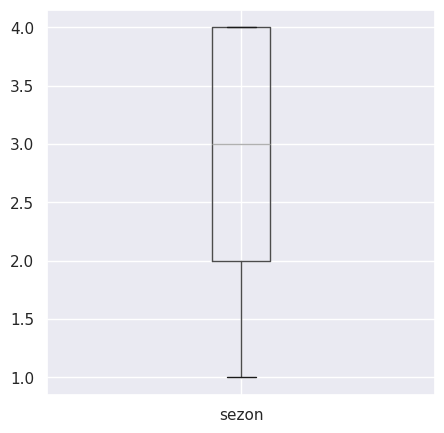

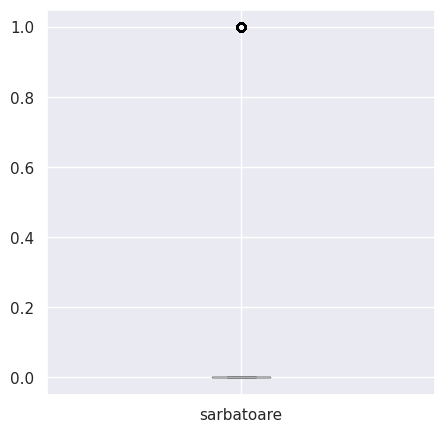

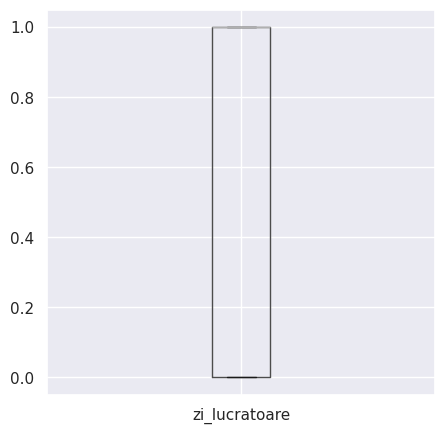

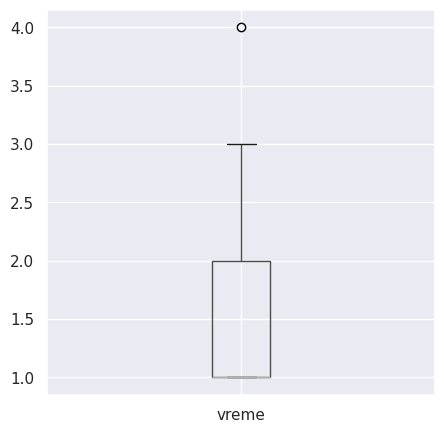

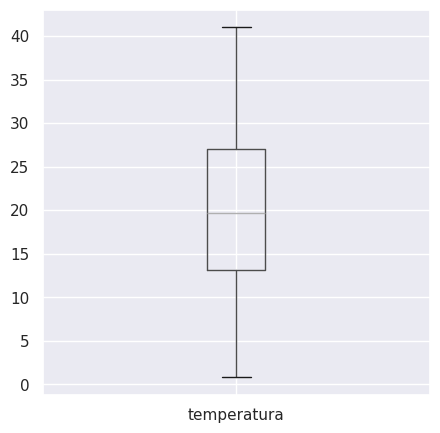

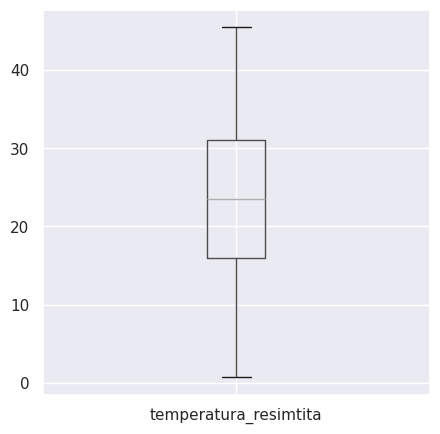

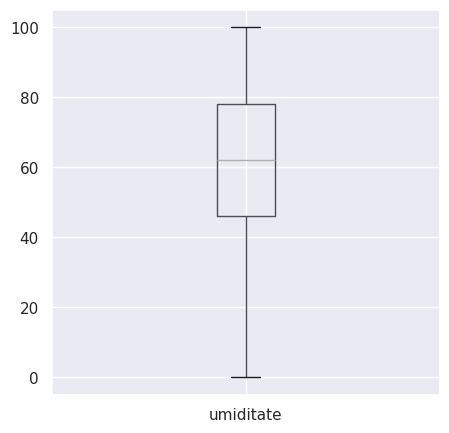

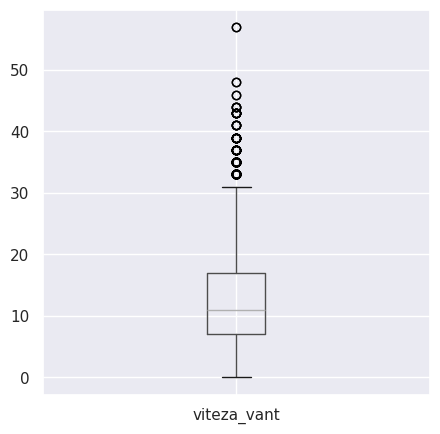

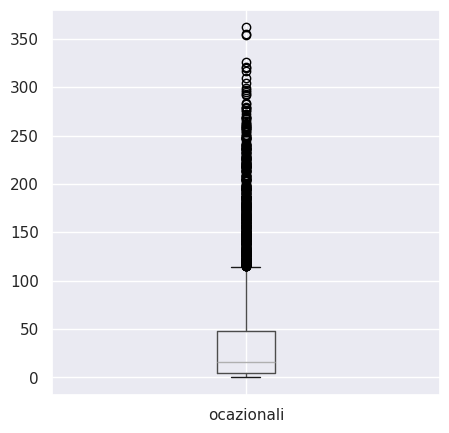

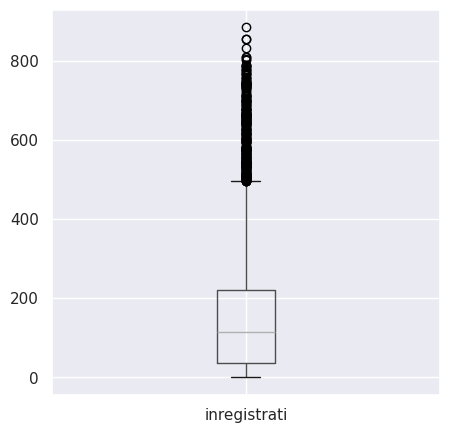

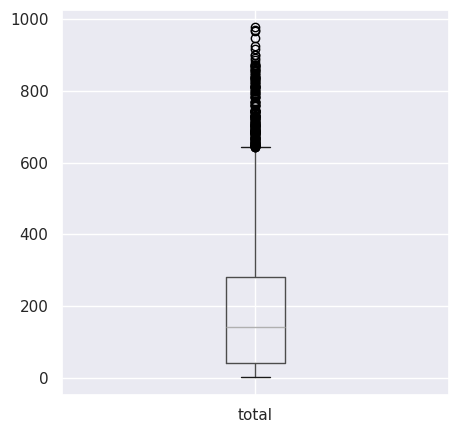

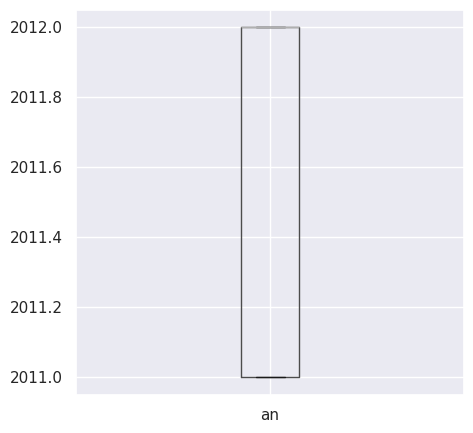

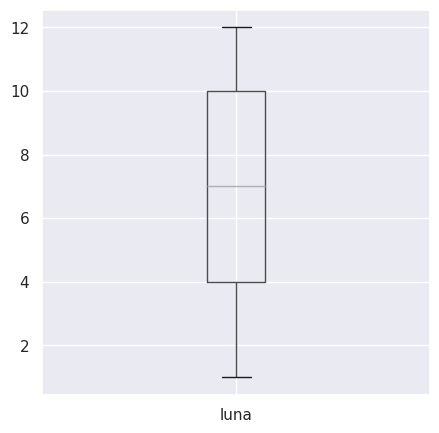

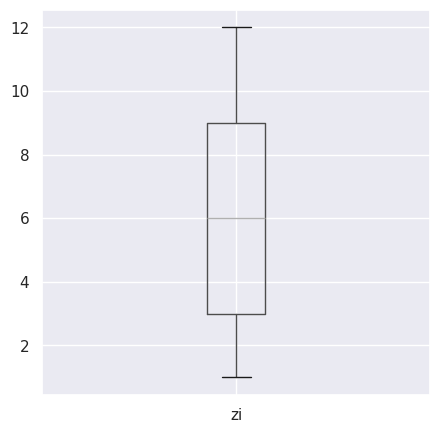

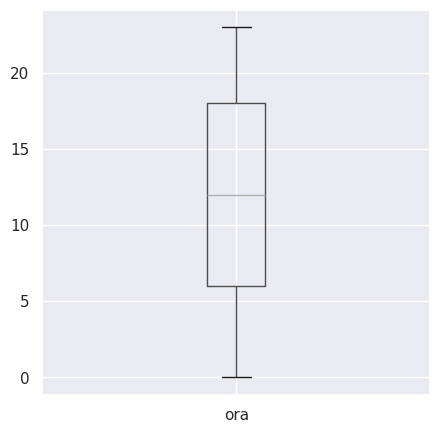

In [ ]:
print('Analiza date individuale:')
sns.set(rc={'figure.figsize': (5, 5)})
number_columns = bycicle_train_set.select_dtypes(include=['int', 'float']).columns
print(number_columns)
for column_to_plot in number_columns:
  bycicle_train_set.boxplot(column=[column_to_plot])
  plt.show()

## Extragerea, standardizarea, selecția de atribute și suplimentarea valorilor lipsă:

In [ ]:
scaler = preprocessing.StandardScaler()


def preprocesare_bycicles(bycicle_set):
    bycicle_set = bycicle_set.drop(['sezon', 'temperatura'], axis=1)
    column_name = list(bycicle_set.columns)
    number_columns = ['vreme', 'viteza_vant']

    important_data = bycicle_set.describe(percentiles=[0.15,0.5,0.85])
    for column_temp in number_columns:
        IQR = important_data[column_temp].iloc[6] - important_data[column_temp].iloc[4]
        bottom_value = important_data[column_temp].iloc[4] - 1.5 * IQR
        top_value = important_data[column_temp].iloc[6] + 1.5 * IQR
        bycicle_set[column_temp] = bycicle_set[column_temp].apply(lambda x: None if x > top_value else x)
        bycicle_set[column_temp] = bycicle_set[column_temp].apply(lambda x: None if x < bottom_value else x)

    imp = IterativeImputer(max_iter=10, random_state=0)
    new_array = imp.fit_transform(bycicle_set)
    bycicle_set_imp_num = pd.DataFrame(new_array)

    scaler = preprocessing.StandardScaler()
    new_array = scaler.fit_transform(bycicle_set_imp_num)
    bycicle_set_imp_num = pd.DataFrame(new_array)

    rename_table = {}
    for i in range(bycicle_set_imp_num.shape[1]):
        rename_table[i] = column_name[i]
    bycicle_set = bycicle_set_imp_num.rename(rename_table, axis = 1)
    return bycicle_set

y_train = bycicle_train_set['total']
X_train = bycicle_train_set.drop(['total','ocazionali','inregistrati'], axis=1)
y_test = bycicle_test_set['total']
X_test = bycicle_test_set.drop(['total','ocazionali','inregistrati'], axis=1)

X_train = preprocesare_bycicles(X_train)
X_test = preprocesare_bycicles(X_test)
display(X_train)
display(X_test)

,sarbatoare,zi_lucratoare,vreme,temperatura_resimtita,umiditate,viteza_vant,an,luna,zi,ora
0,-0.179632,-1.444671,-0.651703,-1.027253,0.958834,-1.553104,-1.002912,-1.601250,-1.592281,-1.669073
1,-0.179632,-1.444671,-0.651703,-1.112944,0.908395,-1.553104,-1.002912,-1.601250,-1.592281,-1.524450
2,-0.179632,-1.444671,-0.651703,-1.112944,0.908395,-1.553104,-1.002912,-1.601250,-1.592281,-1.379827
3,-0.179632,-1.444671,-0.651703,-1.027253,0.656199,-1.553104,-1.002912,-1.601250,-1.592281,-1.235204
4,-0.179632,-1.444671,-0.651703,-1.027253,0.656199,-1.553104,-1.002912,-1.601250,-1.592281,-1.090581
...,...,...,...,...,...,...,...,...,...,...
6873,-0.179632,0.692199,0.906905,-1.027253,-0.302143,0.313706,0.997096,1.590787,1.595230,1.078764
6874,-0.179632,0.692199,-0.651703,-1.027253,-0.503900,0.811466,0.997096,1.590787,1.595230,1.223387
6875,-0.179632,0.692199,0.906905,-1.027253,-0.503900,0.562169,0.997096,1.590787,1.595230,1.368010
6876,-0.179632,0.692199,0.906905,-1.027253,-0.503900,0.313706,0.997096,1.590787,1.595230,1.512633


,sarbatoare,zi_lucratoare,vreme,temperatura_resimtita,umiditate,viteza_vant,an,luna,zi,ora
0,-0.156652,0.671656,-0.676036,-2.305432,-0.148800,0.764578,-1.005504,-1.606343,-1.497525,-1.668721
1,-0.156652,0.671656,-0.676036,-2.305432,-0.643273,0.764578,-1.005504,-1.606343,-1.497525,-1.524154
2,-0.156652,0.671656,-0.676036,-2.305432,-0.643273,1.408850,-1.005504,-1.606343,-1.497525,-1.379588
3,-0.156652,0.671656,-0.676036,-2.305432,-0.643273,1.151487,-1.005504,-1.606343,-1.497525,-1.235021
4,-0.156652,0.671656,-0.676036,-2.305432,-0.643273,0.506351,-1.005504,-1.606343,-1.497525,-1.090454
...,...,...,...,...,...,...,...,...,...,...
4003,-0.156652,0.671656,-0.676036,-0.544519,-0.643273,1.667077,0.994526,1.590391,1.502766,1.078046
4004,-0.156652,0.671656,-0.676036,-0.837681,-0.258683,0.248988,0.994526,1.590391,1.502766,1.222613
4005,-0.156652,0.671656,-0.676036,-1.033338,-0.038917,0.248988,0.994526,1.590391,1.502766,1.367180
4006,-0.156652,0.671656,-0.676036,-0.837681,-0.038917,-0.910875,0.994526,1.590391,1.502766,1.511746


## Utilizarea algoritmilor de Învățare Automată:

### Linear Regresion:

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_pinball_loss, mean_squared_error, mean_absolute_error
from sklearn.model_selection import RandomizedSearchCV
data_table.enable_dataframe_formatter()

def highlight_min(x):
    x_min = x.min()
    return ["font-weight: bold" if v == x_min else "" for v in x]

def highlight_max(x):
    x_max = x.max()
    return ["font-weight: bold" if v == x_max else "" for v in x]

results = []
regr = LinearRegression()
regr.fit(X_train, y_train)
metrics = {"model" : "Linear Regresion"}
y_pred = regr.predict(X_test)
metrics["MAE"] = mean_absolute_error(y_test, y_pred)
metrics["MSE"] = mean_squared_error(y_test, y_pred)
metrics["R2"] = regr.score(X_test, y_test)
results.append(metrics)
pd.DataFrame(results).set_index("model")

,MAE,MSE,R2
model,,,
Linear Regresion,106.007295,20743.69464,0.384324


### SVR:

In [ ]:
from sklearn.svm import SVR


kernels = ['linear', 'poly', 'rbf', 'sigmoid']
degrees = [3, 4]
Cs = [0.4, 1, 1.4, 1.8]
epsilons = [0.1, 0.3]

results = []
for kernel in kernels:
    for degree in degrees:
        for C in Cs:
            for epsilon in epsilons:
                print(f"We are curently at ({kernel}, {degree}, {C}, {epsilon})")
                metrics = {"(kernel, degree, C, epsilon)" : (kernel, degree, C, epsilon)}
                regr = SVR(kernel=kernel, degree=degree, C=C, epsilon=epsilon)
                regr.fit(X_train, y_train)
                y_pred = regr.predict(X_test)
                metrics["MAE"] = mean_absolute_error(y_test, y_pred)
                metrics["MSE"] = mean_squared_error(y_test, y_pred)
                metrics["R2"] = regr.score(X_test, y_test)
                results.append(metrics)

print("SVR (sklearn):")
pd.DataFrame(results).set_index("(kernel, degree, C, epsilon)")

We are curently at (linear, 3, 0.4, 0.1)
We are curently at (linear, 3, 0.4, 0.3)
We are curently at (linear, 3, 1, 0.1)
We are curently at (linear, 3, 1, 0.3)
We are curently at (linear, 3, 1.4, 0.1)
We are curently at (linear, 3, 1.4, 0.3)
We are curently at (linear, 3, 1.8, 0.1)
We are curently at (linear, 3, 1.8, 0.3)
We are curently at (linear, 4, 0.4, 0.1)
We are curently at (linear, 4, 0.4, 0.3)
We are curently at (linear, 4, 1, 0.1)
We are curently at (linear, 4, 1, 0.3)
We are curently at (linear, 4, 1.4, 0.1)
We are curently at (linear, 4, 1.4, 0.3)
We are curently at (linear, 4, 1.8, 0.1)
We are curently at (linear, 4, 1.8, 0.3)
We are curently at (poly, 3, 0.4, 0.1)
We are curently at (poly, 3, 0.4, 0.3)
We are curently at (poly, 3, 1, 0.1)
We are curently at (poly, 3, 1, 0.3)
We are curently at (poly, 3, 1.4, 0.1)
We are curently at (poly, 3, 1.4, 0.3)
We are curently at (poly, 3, 1.8, 0.1)
We are curently at (poly, 3, 1.8, 0.3)
We are curently at (poly, 4, 0.4, 0.1)
We ar

,MAE,MSE,R2
"(kernel, degree, C, epsilon)",,,
"(linear, 3, 0.4, 0.1)",103.317069,23262.172800,0.309575
"(linear, 3, 0.4, 0.3)",103.320523,23266.685513,0.309441
"(linear, 3, 1, 0.1)",103.212074,23126.424599,0.313604
"(linear, 3, 1, 0.3)",103.210840,23125.118062,0.313643
"(linear, 3, 1.4, 0.1)",103.199145,23101.778527,0.314335
...,...,...,...
"(sigmoid, 4, 1, 0.3)",105.039659,24008.172592,0.287433
"(sigmoid, 4, 1.4, 0.1)",105.261622,23868.342853,0.291583
"(sigmoid, 4, 1.4, 0.3)",105.250283,23862.901259,0.291745


### RandomForest Regressor:

In [ ]:
from sklearn.ensemble import RandomForestRegressor

trees = [50, 100, 150, 200]
depths = [2, 4, 6]
procents = [0.2, 0.4, 0.6]

results = []
for tree in trees:
    for depth in depths:
        for procent in procents:
            print(f"We are curently at ({tree}, {depth}, {procent})")
            metrics = {"(tree, depth, percentage)" : (tree, depth, procent)}
            regr = RandomForestRegressor(n_estimators=tree, max_depth=depth, max_samples=procent)
            regr.fit(X_train, y_train)
            y_pred = regr.predict(X_test)
            metrics["MAE"] = mean_absolute_error(y_test, y_pred)
            metrics["MSE"] = mean_squared_error(y_test, y_pred)
            metrics["R2"] = regr.score(X_test, y_test)
            results.append(metrics)

print("Random Forrest Regressor (sklearn):")
pd.DataFrame(results).set_index("(tree, depth, percentage)")

We are curently at (50, 2, 0.2)
We are curently at (50, 2, 0.4)
We are curently at (50, 2, 0.6)
We are curently at (50, 4, 0.2)
We are curently at (50, 4, 0.4)
We are curently at (50, 4, 0.6)
We are curently at (50, 6, 0.2)
We are curently at (50, 6, 0.4)
We are curently at (50, 6, 0.6)
We are curently at (100, 2, 0.2)
We are curently at (100, 2, 0.4)
We are curently at (100, 2, 0.6)
We are curently at (100, 4, 0.2)
We are curently at (100, 4, 0.4)
We are curently at (100, 4, 0.6)
We are curently at (100, 6, 0.2)
We are curently at (100, 6, 0.4)
We are curently at (100, 6, 0.6)
We are curently at (150, 2, 0.2)
We are curently at (150, 2, 0.4)
We are curently at (150, 2, 0.6)
We are curently at (150, 4, 0.2)
We are curently at (150, 4, 0.4)
We are curently at (150, 4, 0.6)
We are curently at (150, 6, 0.2)
We are curently at (150, 6, 0.4)
We are curently at (150, 6, 0.6)
We are curently at (200, 2, 0.2)
We are curently at (200, 2, 0.4)
We are curently at (200, 2, 0.6)
We are curently at 

,MAE,MSE,R2
"(tree, depth, percentage)",,,
"(50, 2, 0.2)",95.699939,18931.973023,0.438096
"(50, 2, 0.4)",98.533645,20019.014664,0.405832
"(50, 2, 0.6)",96.895298,19331.405068,0.426241
"(50, 4, 0.2)",76.161169,12918.282981,0.616583
"(50, 4, 0.4)",77.630426,13330.623073,0.604345
"(50, 4, 0.6)",77.774855,13404.356778,0.602156
"(50, 6, 0.2)",61.239283,9068.389576,0.730849
"(50, 6, 0.4)",60.822874,9042.397078,0.731620
"(50, 6, 0.6)",61.338854,9230.286051,0.726044


### GradientBoosted Regressor:

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

def coverage_fraction(y, y_low, y_high):
    return np.mean(np.logical_and(y >= y_low, y <= y_high))

trees = [50, 100, 150, 200]
depths = [2, 4, 6]
llrs = [0.05, 0.1, 0.2, 0.3]

results = []
for tree in trees:
    for depth in depths:
        for llr in llrs:
            print(f"We are curently at ({tree}, {depth}, {llr})")
            metrics = {"(tree, depth, llr)" : (tree, depth, llr)}
            regr = GradientBoostingRegressor(n_estimators=tree, max_depth=depth, learning_rate=llr)
            regr.fit(X_train, y_train)
            y_pred = regr.predict(X_test)
            metrics["MAE"] = mean_absolute_error(y_test, y_pred)
            metrics["MSE"] = mean_squared_error(y_test, y_pred)
            metrics["R2"] = regr.score(X_test, y_test)
            results.append(metrics)

print("Gradiend Boosted Regressor (sklearn, squared_error):")
display(pd.DataFrame(results).set_index("(tree, depth, llr)"))

all_models = {}
common_params = dict(
    learning_rate=0.05,
    n_estimators=200,
    max_depth=2,
    min_samples_leaf=9,
    min_samples_split=9,
)

for alpha in [0.05, 0.5, 0.95]:
    gbr = GradientBoostingRegressor(loss="quantile", alpha=alpha, **common_params)
    all_models["q %1.2f" % alpha] = gbr.fit(X_train, y_train)

gbr_ls = GradientBoostingRegressor(loss="squared_error", **common_params)
gbr_ls.fit(X_train, y_train)
print("Gradient Boosted Regressor (sklearn, squared_error):")
gbr_ls.score(X_test, y_test)
all_models["mse"] = gbr_ls.fit(X_train, y_train)

results = []
for llr in llrs:
    for depth in depths:
        for tree in trees:
            common_params['n_estimators'] = tree
            common_params['max_depth'] = depth
            common_params['learning_rate'] = llr
            for alpha in [0.05, 0.5, 0.95]:
                print(f"We are at: {tree}, {depth}, {llr}, {alpha}")
                metrics = {"model": ("q %1.2f" % alpha, llr, depth, tree)}
                gbr = GradientBoostingRegressor(loss="quantile", alpha=alpha, **common_params)
                gbr.fit(X_train, y_train)
                y_pred = gbr.predict(X_test)
                for alpha_2 in [0.05, 0.5, 0.95]:
                    metrics["pbl=%1.2f" % alpha_2] = mean_pinball_loss(y_test, y_pred, alpha=alpha_2)
                results.append(metrics)

table = pd.DataFrame(results).set_index("model")
display(table.sort_values(by=['pbl=0.05']))

We are curently at (50, 2, 0.05)
We are curently at (50, 2, 0.1)
We are curently at (50, 2, 0.2)
We are curently at (50, 2, 0.3)
We are curently at (50, 4, 0.05)
We are curently at (50, 4, 0.1)
We are curently at (50, 4, 0.2)
We are curently at (50, 4, 0.3)
We are curently at (50, 6, 0.05)
We are curently at (50, 6, 0.1)
We are curently at (50, 6, 0.2)
We are curently at (50, 6, 0.3)
We are curently at (100, 2, 0.05)
We are curently at (100, 2, 0.1)
We are curently at (100, 2, 0.2)
We are curently at (100, 2, 0.3)
We are curently at (100, 4, 0.05)
We are curently at (100, 4, 0.1)
We are curently at (100, 4, 0.2)
We are curently at (100, 4, 0.3)
We are curently at (100, 6, 0.05)
We are curently at (100, 6, 0.1)
We are curently at (100, 6, 0.2)
We are curently at (100, 6, 0.3)
We are curently at (150, 2, 0.05)
We are curently at (150, 2, 0.1)
We are curently at (150, 2, 0.2)
We are curently at (150, 2, 0.3)
We are curently at (150, 4, 0.05)
We are curently at (150, 4, 0.1)
We are curentl

,MAE,MSE,R2
"(tree, depth, llr)",,,
"(50, 2, 0.05)",83.028616,14350.111067,0.574086
"(50, 2, 0.1)",71.527528,11034.664120,0.672489
"(50, 2, 0.2)",65.703963,8927.035285,0.735044
"(50, 2, 0.3)",62.297735,7761.440415,0.769639
"(50, 4, 0.05)",59.070493,7566.620296,0.775421
"(50, 4, 0.1)",44.569317,4391.220909,0.869668
"(50, 4, 0.2)",38.869348,3489.703319,0.896425
"(50, 4, 0.3)",37.566918,3174.638096,0.905776
"(50, 6, 0.05)",43.535435,4217.880964,0.874813


Gradient Boosted Regressor (sklearn, squared_error):
We are at: 50, 2, 0.05, 0.05
We are at: 50, 2, 0.05, 0.5
We are at: 50, 2, 0.05, 0.95
We are at: 100, 2, 0.05, 0.05
We are at: 100, 2, 0.05, 0.5
We are at: 100, 2, 0.05, 0.95
We are at: 150, 2, 0.05, 0.05
We are at: 150, 2, 0.05, 0.5
We are at: 150, 2, 0.05, 0.95
We are at: 200, 2, 0.05, 0.05
We are at: 200, 2, 0.05, 0.5
We are at: 200, 2, 0.05, 0.95
We are at: 50, 4, 0.05, 0.05
We are at: 50, 4, 0.05, 0.5
We are at: 50, 4, 0.05, 0.95
We are at: 100, 4, 0.05, 0.05
We are at: 100, 4, 0.05, 0.5
We are at: 100, 4, 0.05, 0.95
We are at: 150, 4, 0.05, 0.05
We are at: 150, 4, 0.05, 0.5
We are at: 150, 4, 0.05, 0.95
We are at: 200, 4, 0.05, 0.05
We are at: 200, 4, 0.05, 0.5
We are at: 200, 4, 0.05, 0.95
We are at: 50, 6, 0.05, 0.05
We are at: 50, 6, 0.05, 0.5
We are at: 50, 6, 0.05, 0.95
We are at: 100, 6, 0.05, 0.05
We are at: 100, 6, 0.05, 0.5
We are at: 100, 6, 0.05, 0.95
We are at: 150, 6, 0.05, 0.05
We are at: 150, 6, 0.05, 0.5
We are 

,pbl=0.05,pbl=0.50,pbl=0.95
model,,,
"(q 0.05, 0.2, 6, 150)",4.721136,37.150303,69.579470
"(q 0.05, 0.3, 6, 150)",4.774636,35.906503,67.038369
"(q 0.05, 0.2, 6, 200)",4.792655,37.029034,69.265412
"(q 0.05, 0.1, 6, 200)",4.797089,39.919026,75.040964
"(q 0.05, 0.2, 6, 100)",4.896753,39.828758,74.760763
...,...,...,...
"(q 0.95, 0.05, 2, 150)",147.728169,78.616792,9.505414
"(q 0.95, 0.05, 2, 100)",165.259129,87.863858,10.468586
"(q 0.95, 0.1, 2, 50)",165.565693,88.033125,10.500556


### Quantile Regressor:

In [ ]:
from sklearn.linear_model import QuantileRegressor

results = []
alphas = [0.4, 0.6, 0.8, 1, 1.2, 1.4, 1.6, 1.8, 2]
for alpha in alphas:
    for quantile in [0.05, 0.5, 0.95]:
        print(f"We are at: {quantile}, {alpha}")
        metrics = {"model": ("q %1.2f" % quantile, alpha)}
        gbr = QuantileRegressor(alpha=alpha, quantile=quantile)
        gbr.fit(X_train, y_train)
        y_pred = gbr.predict(X_test)
        for quantile_2 in [0.05, 0.5, 0.95]:
            metrics["pbl=%1.2f" % quantile_2] = mean_pinball_loss(y_test, y_pred, alpha=quantile_2)
        results.append(metrics)

display(pd.DataFrame(results).set_index("model"))
data_table.disable_dataframe_formatter()

We are at: 0.05, 0.4
We are at: 0.5, 0.4
We are at: 0.95, 0.4
We are at: 0.05, 0.6
We are at: 0.5, 0.6
We are at: 0.95, 0.6
We are at: 0.05, 0.8
We are at: 0.5, 0.8
We are at: 0.95, 0.8
We are at: 0.05, 1
We are at: 0.5, 1
We are at: 0.95, 1
We are at: 0.05, 1.2
We are at: 0.5, 1.2
We are at: 0.95, 1.2
We are at: 0.05, 1.4
We are at: 0.5, 1.4
We are at: 0.95, 1.4
We are at: 0.05, 1.6
We are at: 0.5, 1.6
We are at: 0.95, 1.6
We are at: 0.05, 1.8
We are at: 0.5, 1.8
We are at: 0.95, 1.8
We are at: 0.05, 2
We are at: 0.5, 2
We are at: 0.95, 2


,pbl=0.05,pbl=0.50,pbl=0.95
model,,,
"(q 0.05, 0.4)",9.667602,96.166292,182.664983
"(q 0.50, 0.4)",44.947842,69.796532,94.645222
"(q 0.95, 0.4)",346.256275,185.704965,25.153655
"(q 0.05, 0.6)",9.667602,96.166292,182.664983
"(q 0.50, 0.6)",44.947842,69.796532,94.645222
"(q 0.95, 0.6)",346.256275,185.704965,25.153655
"(q 0.05, 0.8)",9.667602,96.166292,182.664983
"(q 0.50, 0.8)",44.947842,69.796532,94.645222
"(q 0.95, 0.8)",346.256275,185.704965,25.153655


# Setul de date "Masini":

## Explorarea și Vizualizarea datelor:


,nume,pret,Oferit de,Are VIN (Serie sasiu),Marca,Model,Versiune,Anul fabricației,Km,Combustibil,...,Electronice si sisteme de asistenta,Siguranta,Norma de poluare,Tara de origine,Data primei inmatriculari,Garantie de la producator pana la,Vehicule electrice,Tuning,Autonomie,Capacitate baterie
0,Opel Astra,3150.0,Firma,NaN,Opel,Astra,NaN,2002,160000.0,Benzina,...,"['Pilot automat', 'Oglinzi exterioare cu regla...","['ABS', 'ESP', 'Airbag sofer', 'Airbag scaun p...",Euro 4,Germania,2002-12-15,NaN,NaN,NaN,NaN,NaN
1,Renault Megane,12495.0,Firma,NaN,Renault,Megane,NaN,2017,159242.0,Diesel,...,"['Pilot automat', 'Senzori parcare fata', 'Sen...","['ABS', 'ESP', 'EBD', 'Franare asistata', 'Sis...",Euro 6,Germania,2017-11-06,NaN,NaN,NaN,NaN,NaN
2,BMW X4 xDrive20d Aut. M Sport,24990.0,Firma,Da,BMW,X4,xDrive20d Aut. M Sport,2016,145000.0,Diesel,...,"['Pilot automat', 'Faruri LED', 'Senzori parca...","['ABS', 'ESP', 'Sistem pre-coliziune lateral',...",Euro 6,NaN,NaN,NaN,['Sistem recuperare energie'],NaN,NaN,NaN
3,Volkswagen Passat 2.0 TDI DSG Highline,22850.0,Firma,Da,Volkswagen,Passat,2.0 TDI DSG Highline,2019,77874.0,Diesel,...,"['Pilot automat adaptiv (distronic)', 'Faruri ...","['ABS', 'ESP', 'Franare asistata', 'Sistem asi...",Euro 6,Romania,2019-12-06,NaN,['Sistem recuperare energie'],NaN,NaN,NaN
4,Volkswagen Golf,7199.0,Firma,Da,Volkswagen,Golf,NaN,2010,230000.0,Benzina,...,"['Pilot automat', 'Servodirectie']","['ABS', 'ESP']",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18983,Porsche 911 Carrera 4S,165886.0,Firma,NaN,Porsche,911,Carrera 4S,2023,7600.0,Benzina,...,"['Adaptive Cruise Control Predictive', 'Faruri...","['ABS', 'ESP', 'Franare asistata', 'Sistem asi...",NaN,Germania,NaN,NaN,NaN,NaN,NaN,NaN
18984,Land Rover Freelander,10990.0,Firma,Da,Land Rover,Freelander,NaN,2011,216286.0,Diesel,...,"['Pilot automat', 'Oglinzi exterioare cu regla...","['ABS', 'EBD', 'Franare asistata', 'Sistem act...",Euro 5,Luxemburg,NaN,NaN,NaN,NaN,NaN,NaN
18985,Ford Tourneo Courier,7200.0,Firma,Da,Ford,Tourneo Courier,NaN,2018,171202.0,Benzina,...,['Servodirectie'],"['ABS', 'ESP', 'Airbag sofer']",Euro 6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
18986,BMW X5 xDrive30d,37450.0,Firma,Da,BMW,X5,xDrive30d,2018,106458.0,Diesel,...,"['Pilot automat', 'Faruri LED', 'Senzori parca...","['ABS', 'ESP', 'EBD', 'Franare asistata', 'Sis...",Euro 6,Germania,NaN,NaN,['Sistem recuperare energie'],NaN,NaN,NaN


This is numerical data:
                pret  Anul fabricației            Km        Putere  \
count   18988.000000      18988.000000  1.894500e+04  18983.000000   
mean    25424.654675       2016.609490  1.381373e+05    179.185587   
std     29824.752654          4.780368  9.048320e+04     93.524671   
min       600.000000       1969.000000  1.000000e+00      3.000000   
25%      9490.000000       2014.000000  6.543000e+04    116.000000   
50%     16500.000000       2018.000000  1.400000e+05    150.000000   
75%     29999.000000       2020.000000  2.030000e+05    200.000000   
max    666666.000000       2024.000000  2.080288e+06   1020.000000   

       Capacitate cilindrica  Consum Extraurban  Consum Urban     Emisii CO2  \
count           18447.000000        8352.000000  13064.000000    9635.000000   
mean             1977.705210           4.879095      6.752013     155.590939   
std               659.091494           1.173531      2.260320    1753.493092   
min               479.000

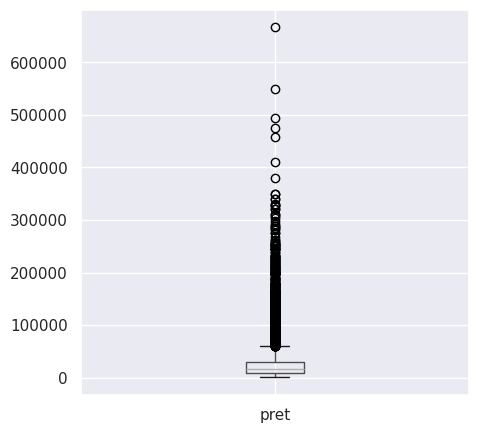

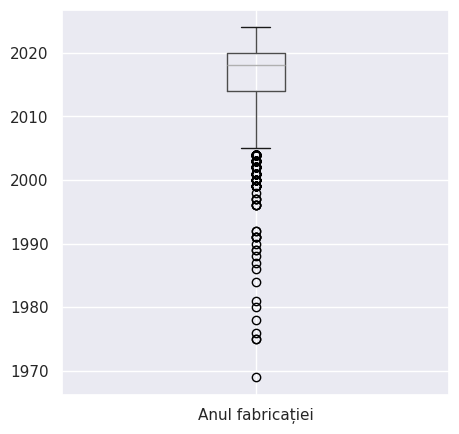

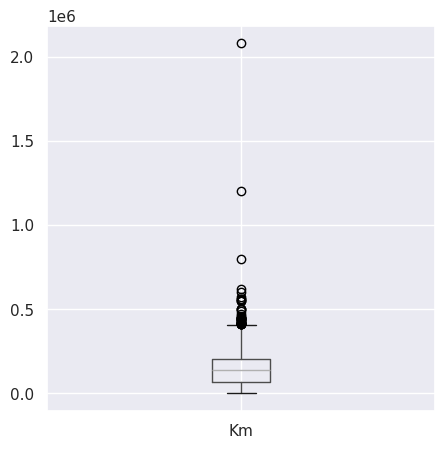

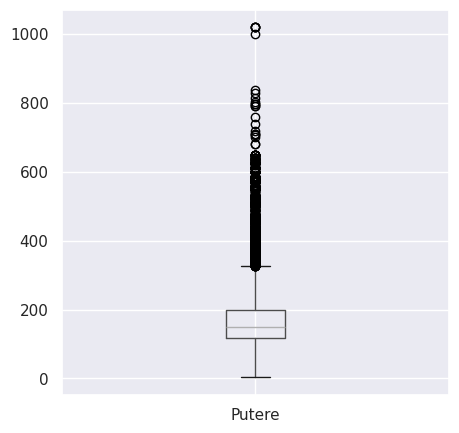

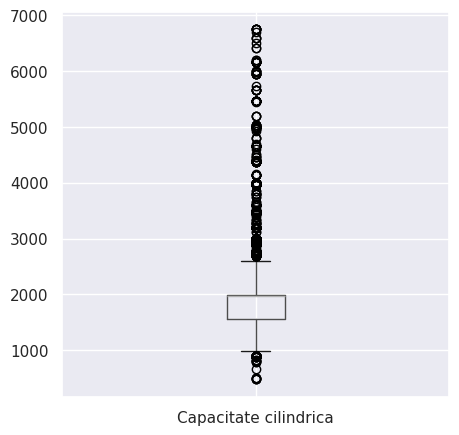

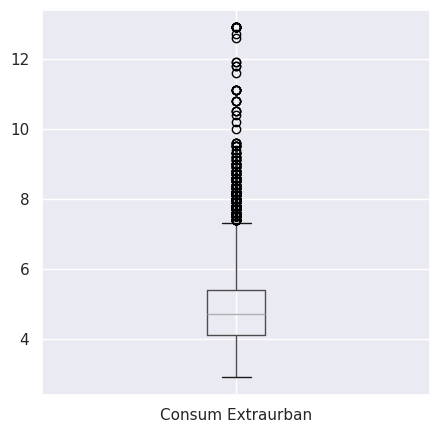

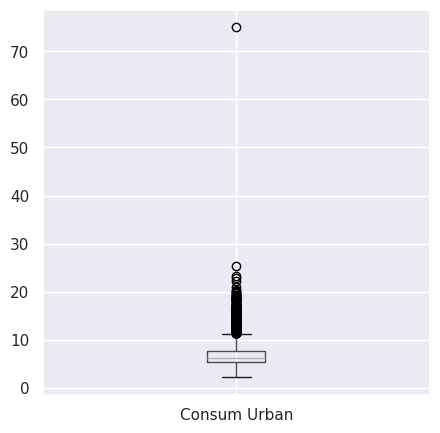

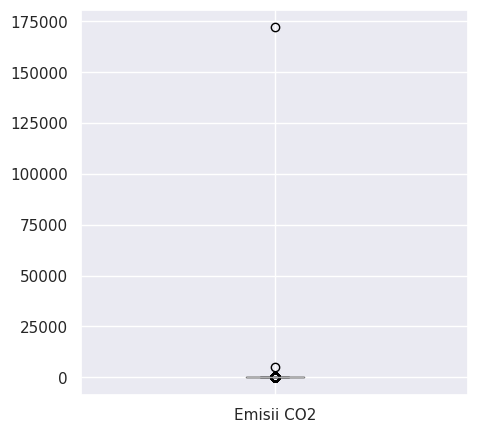

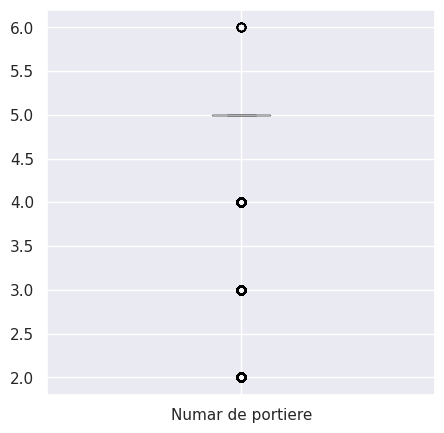

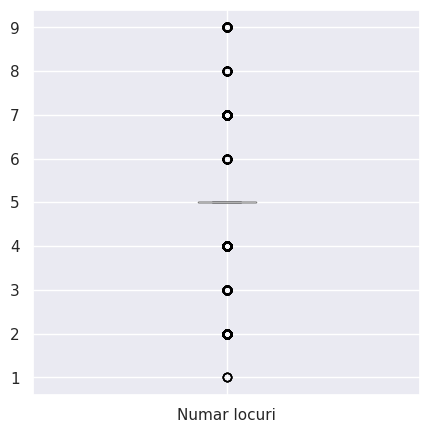

Corelatie intre coloane:


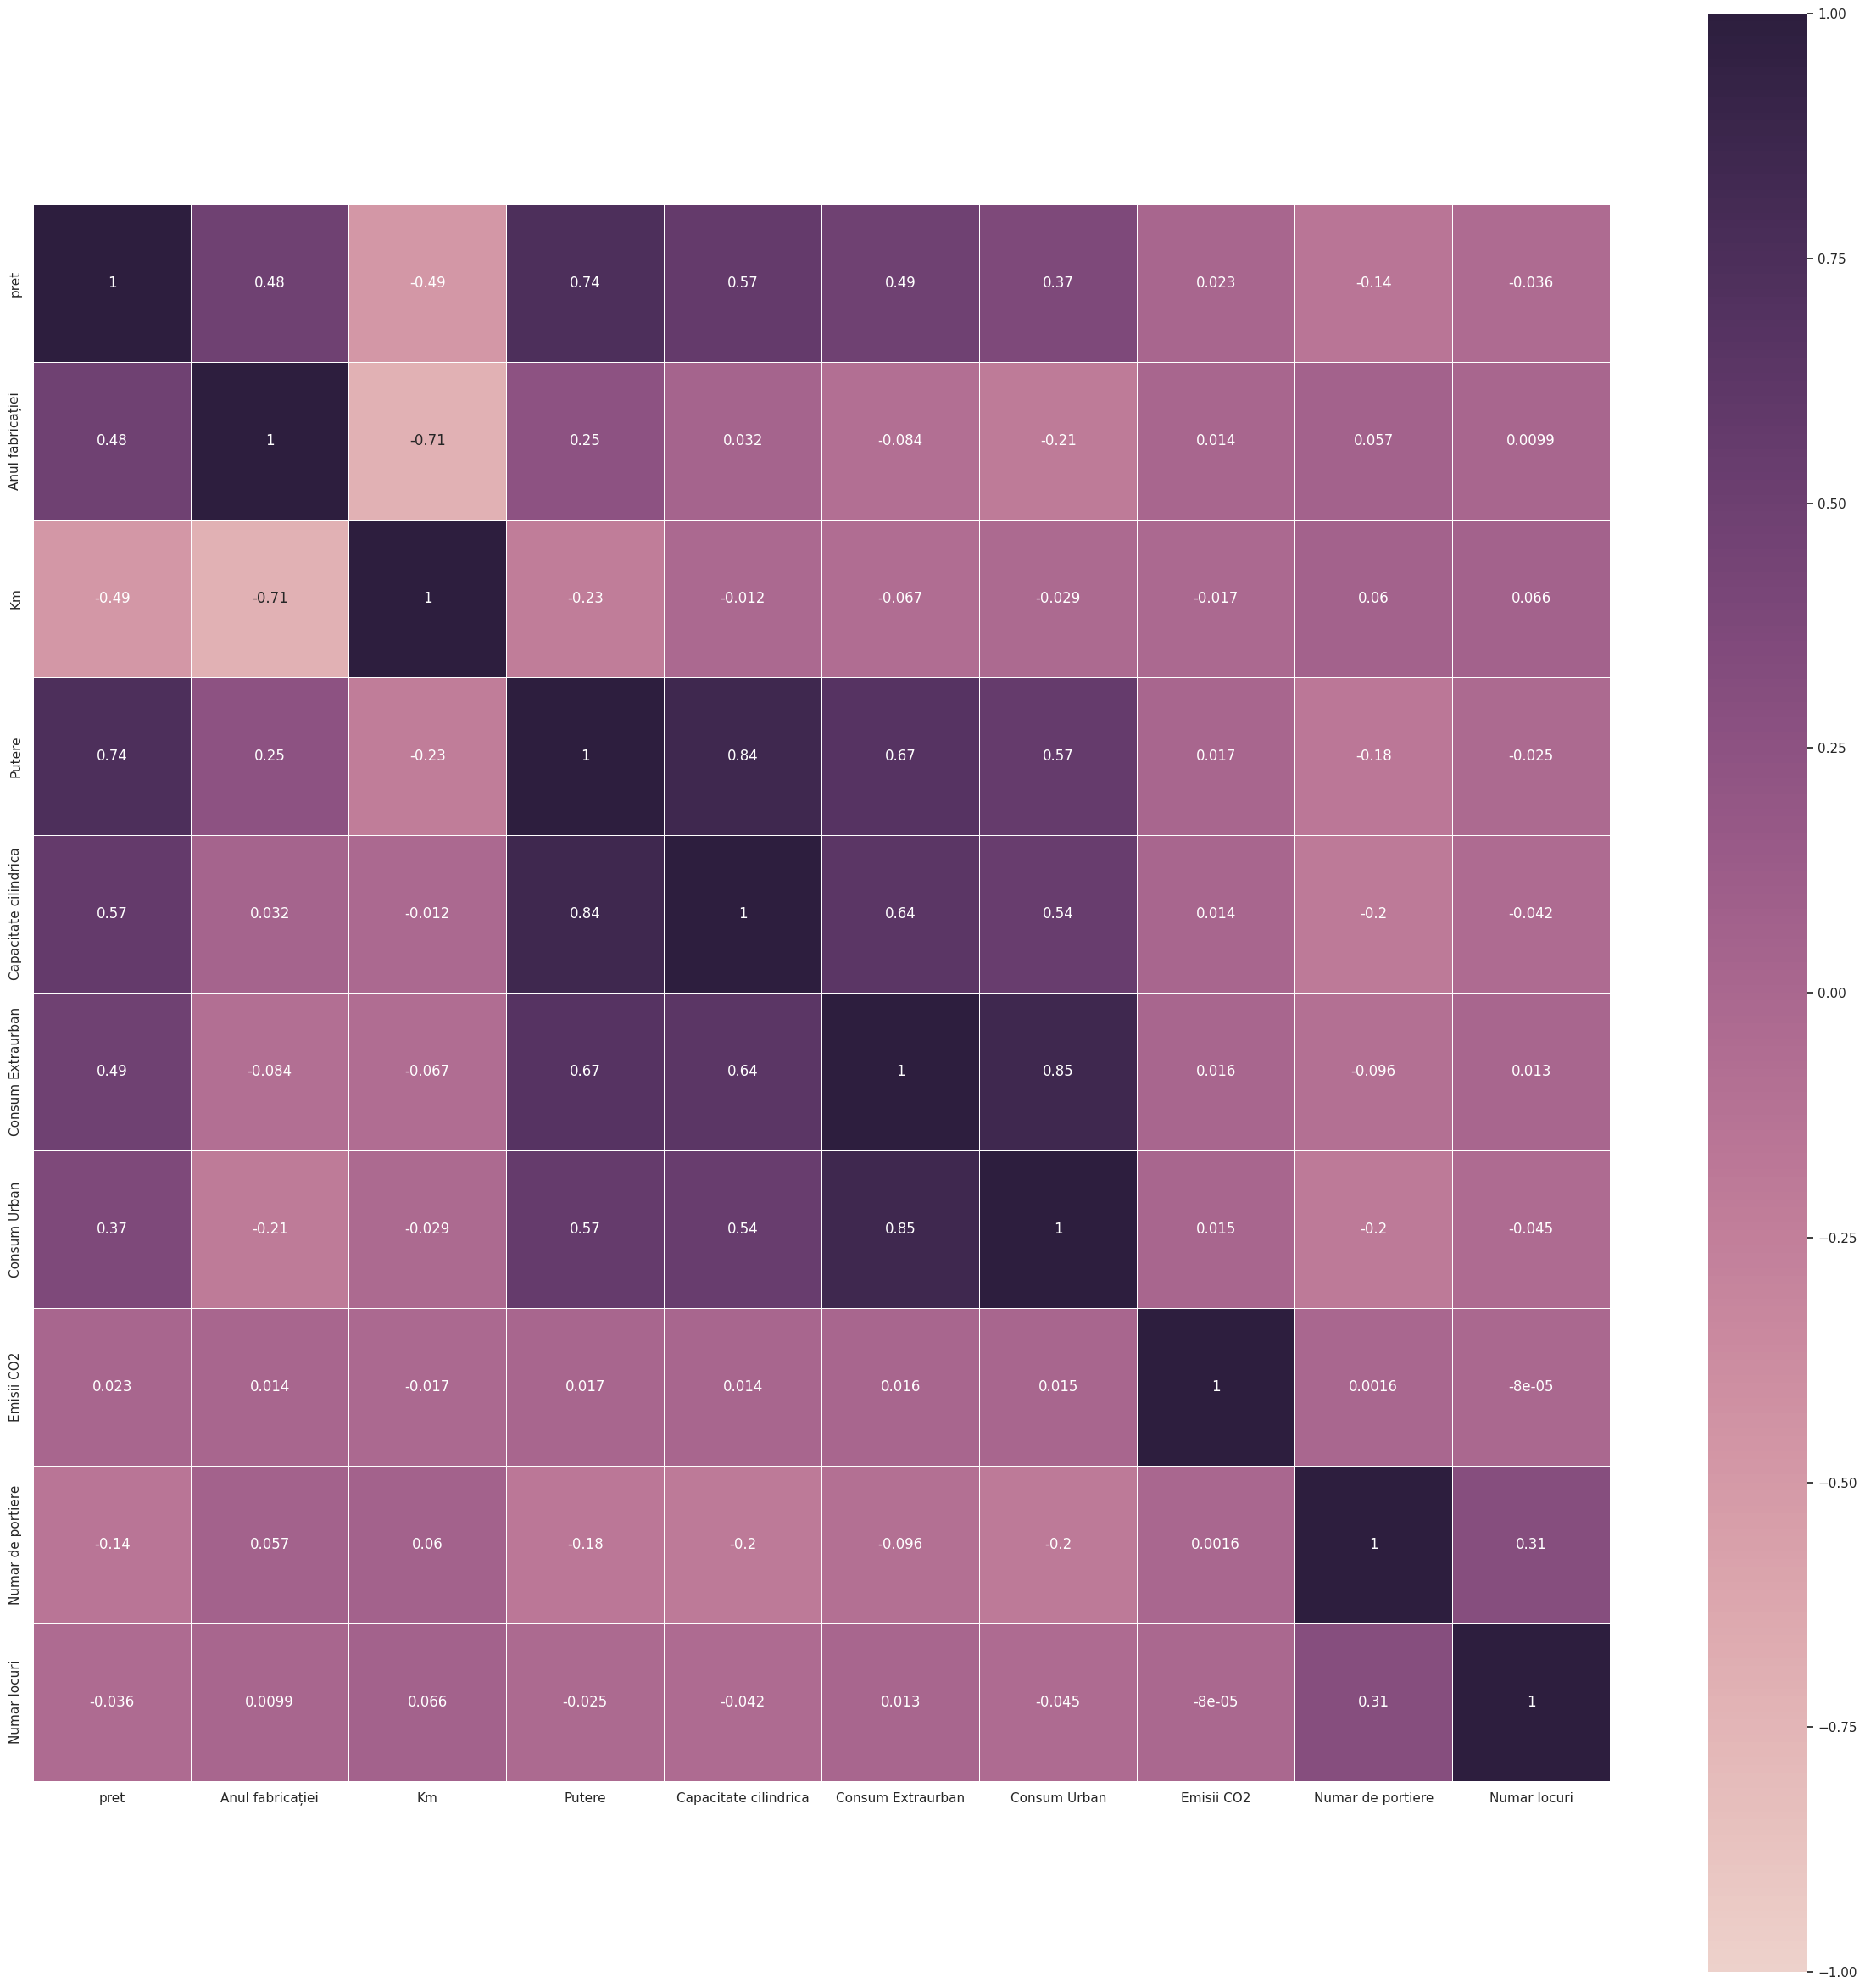

Echilibru clase (train):


/tmp/ipython-input-247513739.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  graph.set_xticklabels(graph.get_xticklabels(), rotation=40, ha="right")


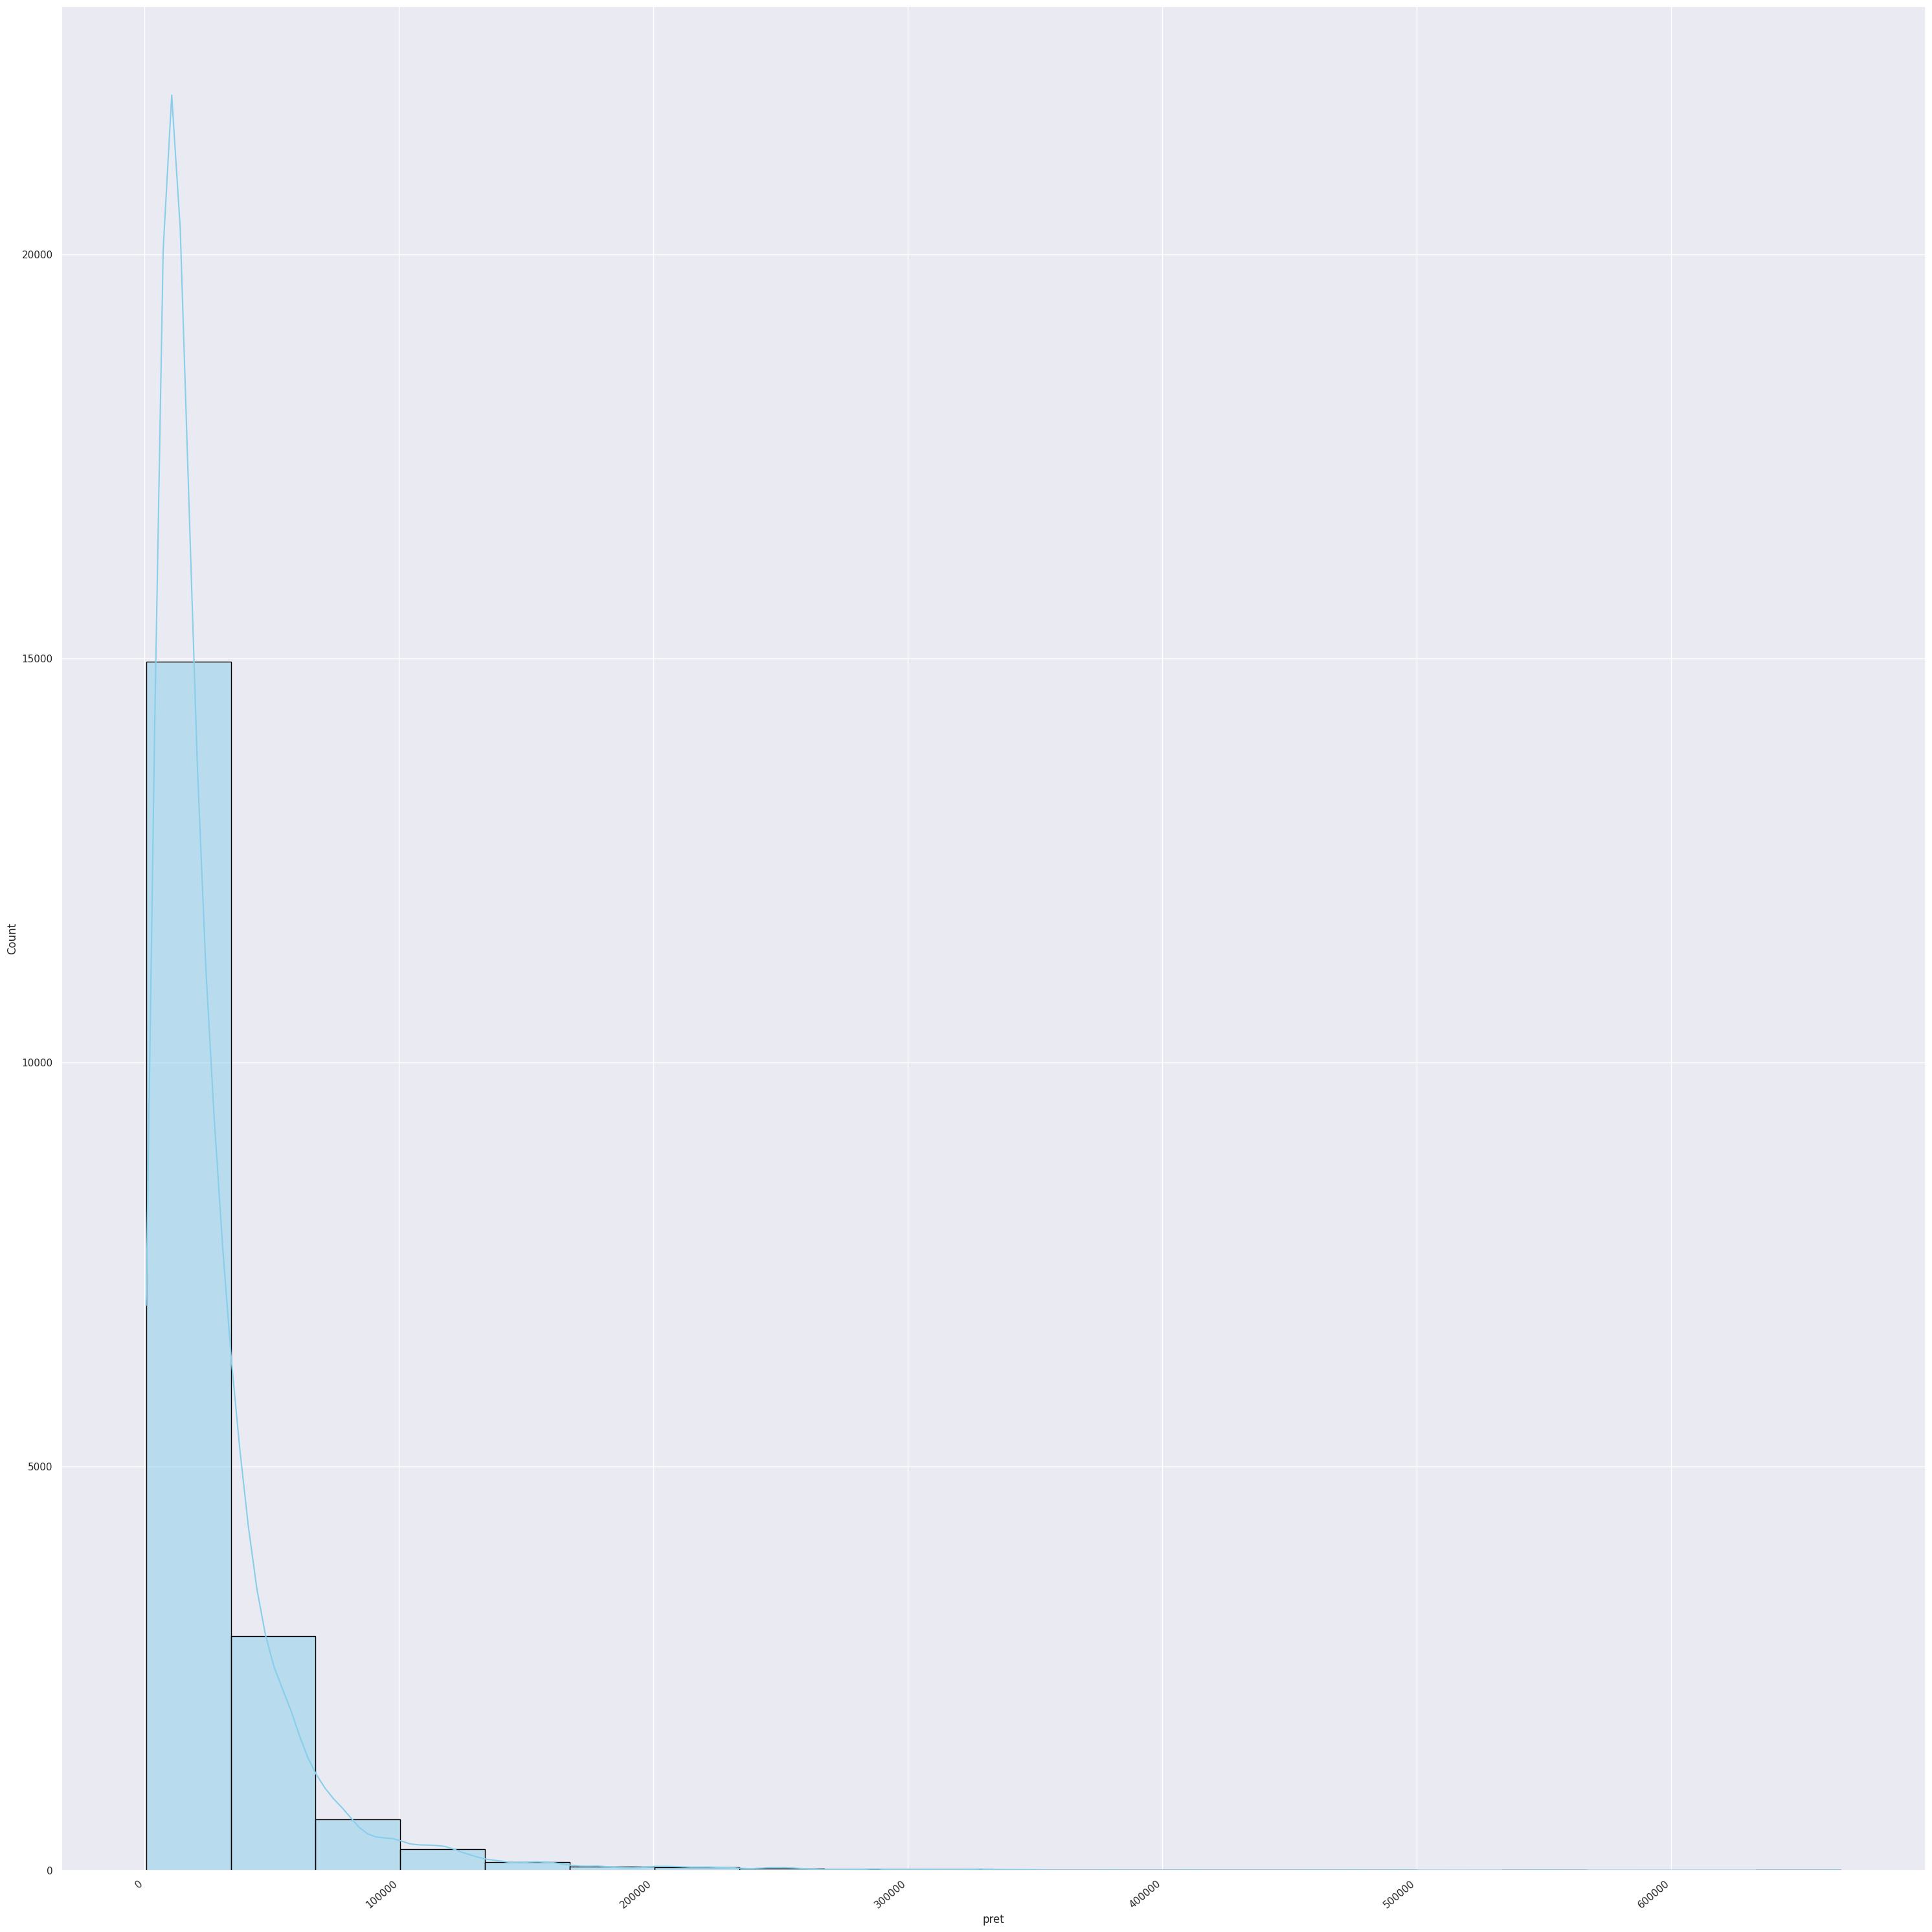

Echilibru clase (test):


/tmp/ipython-input-247513739.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  graph.set_xticklabels(graph.get_xticklabels(), rotation=40, ha="right")


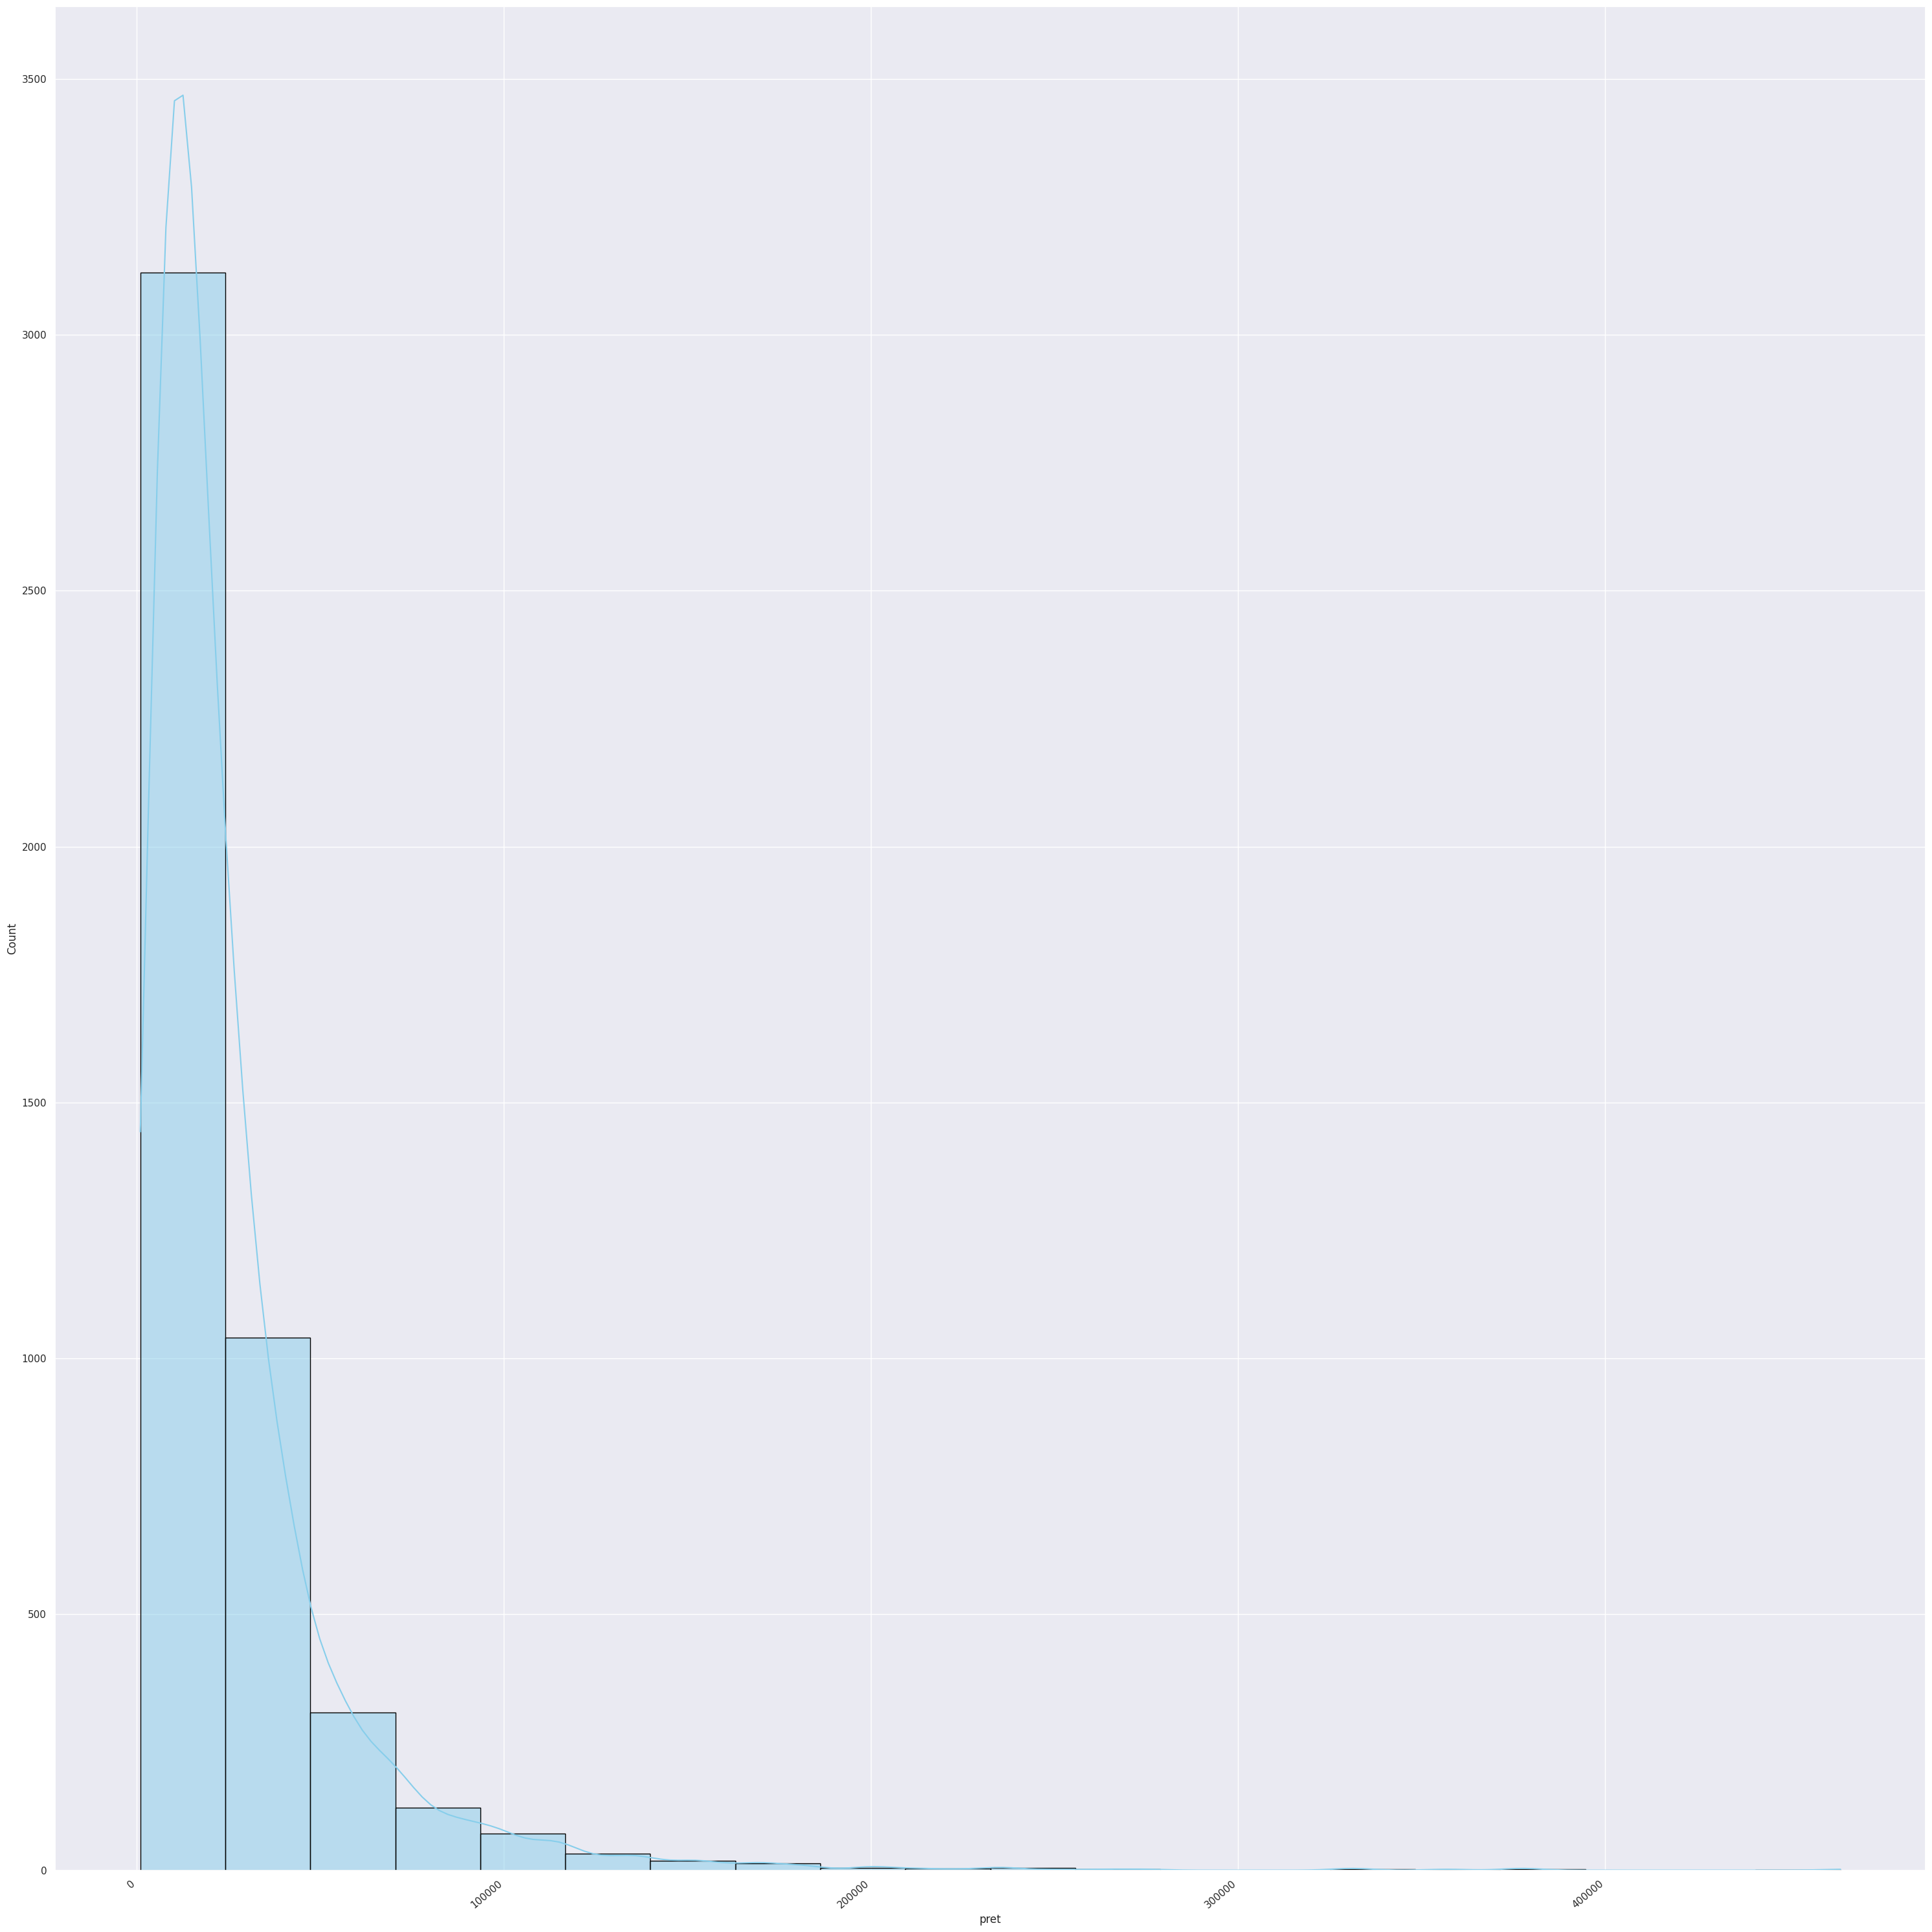

This is the Chi-Test for Marca-Model corelation:
The P-Value of the ChiSq Test is: 0.0
Rejected

This is the Chi-Test for Marca-Versiune corelation:
The P-Value of the ChiSq Test is: 0.0
Rejected

This is the Chi-Test for Marca-Combustibil corelation:
The P-Value of the ChiSq Test is: 0.0
Rejected

This is the Chi-Test for Marca-Transmisie corelation:
The P-Value of the ChiSq Test is: 0.0
Rejected

This is the Chi-Test for Marca-Cutie de viteze corelation:
The P-Value of the ChiSq Test is: 0.0
Rejected

This is the Chi-Test for Marca-Tip Caroserie corelation:
The P-Value of the ChiSq Test is: 0.0
Rejected

This is the Chi-Test for Marca-Culoare corelation:
The P-Value of the ChiSq Test is: 0.0
Rejected

This is the Chi-Test for Marca-Garantie dealer (inclusa in pret) corelation:
The P-Value of the ChiSq Test is: 0.0
Rejected

This is the Chi-Test for Marca-Primul proprietar (de nou) corelation:
The P-Value of the ChiSq Test is: 1.0
Accepted

This is the Chi-Test for Marca-Fara accident

In [ ]:
display(cars_train_set)

print('This is numerical data:')
print(cars_train_set.describe())

print()
print('This is categorical data:')
print(cars_train_set.describe(include=[object]))

print()
number_columns = cars_train_set.select_dtypes(include=['int', 'float']).columns
object_columns = cars_train_set.select_dtypes(include=[object]).columns
print(number_columns)
for column_to_plot in number_columns:
  cars_train_set.boxplot(column=[column_to_plot])
  plt.show()

print('Corelatie intre coloane:')
corr_matrix = cars_train_set[number_columns].corr(method='pearson')
sns.set(rc={'figure.figsize': (30, 30)})
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap=sns.cubehelix_palette(as_cmap=True),
    vmin=-1, vmax=1,
    center=0,
    linewidths=0.5,
    square=True
)
plt.show()

print('Echilibru clase (train):')
graph = sns.histplot(cars_train_set['pret'], bins=20, kde=True, color='skyblue', edgecolor='black')
graph.set_xticklabels(graph.get_xticklabels(), rotation=40, ha="right")
plt.tight_layout()
plt.show()

print('Echilibru clase (test):')
graph = sns.histplot(cars_test_set['pret'], bins=20, kde=True, color='skyblue', edgecolor='black')
graph.set_xticklabels(graph.get_xticklabels(), rotation=40, ha="right")
plt.tight_layout()
plt.show()

len_non_numeric = len(object_columns)
for i in range(3, len_non_numeric):
  for j in range(i + 1, len_non_numeric):
    print(f'This is the Chi-Test for {object_columns[i]}-{object_columns[j]} corelation:')
    CrosstabResult=pd.crosstab(index=cars_train_set[object_columns[i]], columns=cars_train_set[object_columns[j]])
    ChiSqResult = chi2_contingency(CrosstabResult)
    print('The P-Value of the ChiSq Test is:', ChiSqResult[1])
    if ChiSqResult[1] > 0.05:
      print("Accepted\n")
    else:
      print("Rejected\n")

## Extragerea, standardizarea, selecția de atribute și suplimentarea valorilor lipsă:

In [ ]:
from ast import literal_eval
pd.set_option('display.max_columns', None)

def preprocesare_cars(cars):
    column_numerical = cars.select_dtypes(include=['int', 'float']).columns
    column_non_numerical = cars.select_dtypes(include=['object']).columns

    cars_numerical = cars[column_numerical]
    cars_non_numerical = cars[column_non_numerical]
    cars_numerical = cars_numerical
    cars_non_numerical = cars_non_numerical.drop(['Versiune', 'nume'], axis=1)

    important_data = cars_numerical.describe(percentiles=[0.15,0.5,0.85])
    for column_temp in column_numerical:
        IQR = important_data[column_temp].iloc[6] - important_data[column_temp].iloc[4]
        bottom_value = important_data[column_temp].iloc[4] - 1.5 * IQR
        top_value = important_data[column_temp].iloc[6] + 1.5 * IQR
        cars_numerical[column_temp] = cars_numerical[column_temp].apply(lambda x: None if x > top_value else x)
        cars_numerical[column_temp] = cars_numerical[column_temp].apply(lambda x: None if x < bottom_value else x)

    cars_non_numerical['Siguranta'] = cars_non_numerical['Siguranta'].apply(lambda x: literal_eval(x) if(np.all(pd.notnull(x))) else [])
    df_siguranta = pd.DataFrame(cars_non_numerical['Siguranta'].tolist()).apply(pd.Series.value_counts, axis=1).fillna(0).astype(int)
    cars_non_numerical['Electronice si sisteme de asistenta'] = cars_non_numerical['Electronice si sisteme de asistenta'].apply(lambda x: literal_eval(x) if(np.all(pd.notnull(x))) else [])
    df_electronice = pd.DataFrame(cars_non_numerical['Electronice si sisteme de asistenta'].tolist()).apply(pd.Series.value_counts, axis=1).fillna(0).astype(int)
    cars_non_numerical['Audio si tehnologie'] = cars_non_numerical['Audio si tehnologie'].apply(lambda x: literal_eval(x) if(np.all(pd.notnull(x))) else [])
    df_audio = pd.DataFrame(cars_non_numerical['Audio si tehnologie'].tolist()).apply(pd.Series.value_counts, axis=1).fillna(0).astype(int)
    cars_non_numerical['Confort si echipamente optionale'] = cars_non_numerical['Confort si echipamente optionale'].apply(lambda x: literal_eval(x) if(np.all(pd.notnull(x))) else [])
    df_confort = pd.DataFrame(cars_non_numerical['Confort si echipamente optionale'].tolist()).apply(pd.Series.value_counts, axis=1).fillna(0).astype(int)
    cars_non_numerical['Vehicule electrice'] = cars_non_numerical['Vehicule electrice'].apply(lambda x: literal_eval(x) if(np.all(pd.notnull(x))) else [])
    df_electrice = pd.DataFrame(cars_non_numerical['Vehicule electrice'].tolist()).apply(pd.Series.value_counts, axis=1).fillna(0).astype(int)
    cars_non_numerical = cars_non_numerical.drop(['Siguranta', 'Electronice si sisteme de asistenta', 'Audio si tehnologie', 'Confort si echipamente optionale', 'Vehicule electrice'], axis=1)

    df_vinieta = cars_non_numerical['Are VIN (Serie sasiu)'].apply(lambda x: 1 if(np.all(pd.notnull(x))) else 0)
    df_propr = cars_non_numerical['Primul proprietar (de nou)'].apply(lambda x: 1 if(np.all(pd.notnull(x))) else 0)
    df_accident = cars_non_numerical['Fara accident in istoric'].apply(lambda x: 1 if(np.all(pd.notnull(x))) else 0)
    df_tuning = cars_non_numerical['Tuning'].apply(lambda x: 1 if(np.all(pd.notnull(x))) else 0)
    df_data_prima = cars_non_numerical['Data primei inmatriculari'].apply(lambda x: 1 if(np.all(pd.notnull(x))) else 0)
    df_garant = cars_non_numerical['Garantie dealer (inclusa in pret)'].apply(lambda x: 1 if(np.all(pd.notnull(x))) else 0)
    cars_non_numerical = cars_non_numerical.drop(['Are VIN (Serie sasiu)', 'Primul proprietar (de nou)', 'Fara accident in istoric', 'Tuning', 'Data primei inmatriculari', 'Garantie dealer (inclusa in pret)', 'Garantie de la producator pana la'], axis=1)

    column_non_numerical = column_non_numerical.drop(['nume', 'Are VIN (Serie sasiu)', 'Primul proprietar (de nou)', 'Fara accident in istoric', 'Tuning', 'Data primei inmatriculari', 'Garantie dealer (inclusa in pret)', 'Garantie de la producator pana la',
                               'Versiune', 'Siguranta', 'Electronice si sisteme de asistenta', 'Audio si tehnologie', 'Confort si echipamente optionale', 'Vehicule electrice'])
    print(column_non_numerical)
    display(cars_non_numerical.describe(include=["object"]))

    imp = IterativeImputer(max_iter=10, random_state=0)
    new_array = imp.fit_transform(cars_numerical)
    cars_numerical_imp_num = pd.DataFrame(new_array)
    rename_table = {}
    for i in range(cars_numerical_imp_num.shape[1]):
        rename_table[i] = column_numerical[i]
    cars_numerical = cars_numerical_imp_num.rename(rename_table, axis = 1)

    imp = SimpleImputer(strategy='most_frequent')
    new_array = imp.fit_transform(cars_non_numerical)
    cars_non_numerical_imp_str = pd.DataFrame(new_array)
    rename_table = {}
    for i in range(cars_non_numerical_imp_str.shape[1]):
        rename_table[i] = column_non_numerical[i]
    cars_non_numerical = cars_non_numerical_imp_str.rename(rename_table, axis = 1)

    df_capacitate = cars_non_numerical['Capacitate baterie'].apply(lambda x: int(x.replace(x.lstrip('0123456789'), '')) if(np.all(pd.notnull(x))) else x)
    df_range = cars_non_numerical['Autonomie'].apply(lambda x: int(x.replace(x.lstrip('0123456789'), '')) if(np.all(pd.notnull(x))) else x)
    cars_non_numerical = cars_non_numerical.drop(['Capacitate baterie', 'Autonomie', 'Model'], axis=1)

    cars_non_numerical = pd.get_dummies(cars_non_numerical, dtype=float)
    print()
    print("THIS IS CARS NON NUMERICAL AFTER PREPROCESARE")
    display(cars_non_numerical)

    print()
    print("THIS IS CARS NUMERICAL AFTER PREPROCESARE")
    display(cars_numerical)

    list_df = [cars_numerical, cars_non_numerical, df_range, df_capacitate, df_garant, df_data_prima, df_tuning, df_accident,
                                df_propr, df_vinieta, df_electrice, df_confort, df_audio, df_electronice, df_siguranta]
    for df in list_df:
        print()
        print()
        display(df)

    cars_numerical = pd.concat(list_df, axis=1)

    column_name = cars_numerical.columns
    print(column_name)
    scaler = preprocessing.StandardScaler()
    new_array = scaler.fit_transform(cars_numerical)
    cars_numerical = pd.DataFrame(new_array)

    rename_table = {}
    for i in range(cars_numerical.shape[1]):
        rename_table[i] = column_name[i]
    cars_numerical = cars_numerical.rename(rename_table, axis = 1)

    display(cars_numerical.describe())
    display(cars_numerical)

    return cars_numerical


y_train = cars_train_set['pret']
X_train = cars_train_set.drop('pret', axis=1)
y_test = cars_test_set['pret']
X_test = cars_test_set.drop('pret', axis=1)

X_total = pd.concat([X_train, X_test], ignore_index=True)
display(X_total)
X_total = preprocesare_cars(X_total)

X_train = X_total.head(cars_train_set.shape[0])
X_train = X_train.reindex(range(X_train.shape[0]))

X_test = X_total.tail(cars_test_set.shape[0])
X_test.index = range(X_test.shape[0])
print()
print()
print()
display(X_train)
display(y_train)
display(X_test)
display(y_test)

,nume,Oferit de,Are VIN (Serie sasiu),Marca,Model,Versiune,Anul fabricației,Km,Combustibil,Putere,Capacitate cilindrica,Transmisie,Consum Extraurban,Cutie de viteze,Consum Urban,Tip Caroserie,Emisii CO2,Numar de portiere,Culoare,Numar locuri,Garantie dealer (inclusa in pret),Primul proprietar (de nou),Fara accident in istoric,Stare,Audio si tehnologie,Confort si echipamente optionale,Electronice si sisteme de asistenta,Siguranta,Norma de poluare,Tara de origine,Data primei inmatriculari,Garantie de la producator pana la,Vehicule electrice,Tuning,Autonomie,Capacitate baterie
0,Opel Astra,Firma,NaN,Opel,Astra,NaN,2002,160000.0,Benzina,100.0,1598.0,Fata,NaN,Automata,9.6,Compacta,NaN,5.0,Argint,5.0,NaN,Da,Da,Second hand,"['Radio', 'Sistem audio']","['Climatronic', 'Top stofa', 'Tapiterie stofa'...","['Pilot automat', 'Oglinzi exterioare cu regla...","['ABS', 'ESP', 'Airbag sofer', 'Airbag scaun p...",Euro 4,Germania,2002-12-15,NaN,NaN,NaN,NaN,NaN
1,Renault Megane,Firma,NaN,Renault,Megane,NaN,2017,159242.0,Diesel,110.0,1461.0,Fata,NaN,Manuala,NaN,Combi,NaN,4.0,Albastru,5.0,12 luni,NaN,Da,Second hand,"['Bluetooth', 'Radio', 'Sistem navigatie', 'Si...","['Carlig remorcare', 'Climatronic', 'Trapa ele...","['Pilot automat', 'Senzori parcare fata', 'Sen...","['ABS', 'ESP', 'EBD', 'Franare asistata', 'Sis...",Euro 6,Germania,2017-11-06,NaN,NaN,NaN,NaN,NaN
2,BMW X4 xDrive20d Aut. M Sport,Firma,Da,BMW,X4,xDrive20d Aut. M Sport,2016,145000.0,Diesel,190.0,1995.0,4x4 (automat),4.9,Automata,5.3,SUV,132.0,5.0,Albastru,5.0,NaN,Da,Da,Second hand,"['Bluetooth', 'Radio', 'Sistem hands-free', 'P...","['Climatronic 2 zone', 'Trapa electrica', 'Tap...","['Pilot automat', 'Faruri LED', 'Senzori parca...","['ABS', 'ESP', 'Sistem pre-coliziune lateral',...",Euro 6,NaN,NaN,NaN,['Sistem recuperare energie'],NaN,NaN,NaN
3,Volkswagen Passat 2.0 TDI DSG Highline,Firma,Da,Volkswagen,Passat,2.0 TDI DSG Highline,2019,77874.0,Diesel,150.0,1968.0,Fata,NaN,Automata,4.4,Sedan,NaN,4.0,Argint,5.0,12 luni,Da,Da,Second hand,"['Apple Carplay', 'Android Auto', 'Bluetooth',...","['Climatronic 3 zone', 'Tapiterie mixta piele-...","['Pilot automat adaptiv (distronic)', 'Faruri ...","['ABS', 'ESP', 'Franare asistata', 'Sistem asi...",Euro 6,Romania,2019-12-06,NaN,['Sistem recuperare energie'],NaN,NaN,NaN
4,Volkswagen Golf,Firma,Da,Volkswagen,Golf,NaN,2010,230000.0,Benzina,122.0,1390.0,Fata,NaN,Automata,NaN,Compacta,NaN,5.0,Negru,5.0,12 luni,NaN,Da,Second hand,"['Radio', 'Sistem hands-free', 'Sistem audio']","['Climatronic 2 zone', 'Tapiterie alcantara', ...","['Pilot automat', 'Servodirectie']","['ABS', 'ESP']",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23729,Dacia Duster,Firma,NaN,Dacia,Duster,NaN,2019,60150.0,Diesel,116.0,1461.0,NaN,NaN,Manuala,NaN,SUV,NaN,5.0,Negru,5.0,NaN,NaN,NaN,Second hand,"['Android Auto', 'Bluetooth', 'Radio', 'Port U...","['Climatronic', 'Tapiterie stofa', 'Volan cu c...","['Pilot automat', 'Senzori parcare spate', 'Og...","['ABS', 'ESP', 'Airbag sofer', 'Airbag lateral...",Euro 6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
23730,Renault Espace Energy TCe 200 EDC Intens,Privat,NaN,Renault,Espace,Energy TCe 200 EDC Intens,2017,220000.0,Benzina,200.0,1618.0,NaN,NaN,Automata,8.7,Monovolum,NaN,5.0,Gri,5.0,NaN,NaN,NaN,Second hand,"['Apple Carplay', 'Android Auto', 'Bluetooth',...","['Climatronic 2 zone', 'Plafon panoramic', 'Ta...","['Pilot automat adaptiv (distronic)', 'Faruri ...","['ABS', 'ESP', 'EBD', 'Franare asistata', 'Sis...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
23731,Ford Focus,Firma,NaN,Ford,Focus,NaN,2019,163349.0,Diesel,120.0,1498.0,Fata,NaN,Manuala,5.9,Sedan,105.0,4.0,Alb,5.0,3 luni,Da,Da,Second hand,"['Apple Carplay', 'Android Auto', 'Bluetooth',...","['Climatronic 2 zone', 'Top stofa', 'Incalzire...","['Pilot automat', 'Oglinzi exterioare cu regla...","['ABS', 'ESP', 'Franare asistata', 'Sistem asi...",Euro 6,Romania,NaN,NaN,N

/tmp/ipython-input-1975145185.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cars_numerical[column_temp] = cars_numerical[column_temp].apply(lambda x: None if x > top_value else x)
/tmp/ipython-input-1975145185.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cars_numerical[column_temp] = cars_numerical[column_temp].apply(lambda x: None if x < bottom_value else x)


Index(['Oferit de', 'Marca', 'Model', 'Combustibil', 'Transmisie',
       'Cutie de viteze', 'Tip Caroserie', 'Culoare', 'Stare',
       'Norma de poluare', 'Tara de origine', 'Autonomie',
       'Capacitate baterie'],
      dtype='object')


,Oferit de,Marca,Model,Combustibil,Transmisie,Cutie de viteze,Tip Caroserie,Culoare,Stare,Norma de poluare,Tara de origine,Autonomie,Capacitate baterie
count,23734,23734,23734,23734,21093,23733,23734,23734,23734,16060,14031,423,400
unique,2,66,643,8,4,2,9,12,2,13,31,170,81
top,Firma,Mercedes-Benz,Octavia,Diesel,Fata,Automata,SUV,Negru,Second hand,Euro 6,Germania,160 km,18 kWh
freq,16297,3057,637,14662,10647,15282,9579,5990,22051,10016,5735,25,35


/usr/local/lib/python3.12/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


...

,Anul fabricației,Km,Putere,Capacitate cilindrica,Consum Extraurban,Consum Urban,Emisii CO2,Numar de portiere,Numar locuri,Oferit de_Firma,Oferit de_Privat,Marca_Abarth,Marca_Aixam,Marca_Alfa Romeo,Marca_Altul,Marca_Aston Martin,Marca_Audi,Marca_BMW,Marca_Baic,Marca_Bentley,Marca_Cadillac,Marca_Chevrolet,Marca_Chrysler,Marca_Citroën,Marca_Cupra,Marca_DS Automobiles,Marca_Dacia,Marca_Daewoo,Marca_Daihatsu,Marca_Dodge,Marca_Ferrari,Marca_Fiat,Marca_Ford,Marca_Honda,Marca_Hyundai,Marca_Ineos,Marca_Infiniti,Marca_Isuzu,Marca_Iveco,Marca_Jaguar,Marca_Jeep,Marca_Kia,Marca_Lamborghini,Marca_Lancia,Marca_Land Rover,Marca_Lexus,Marca_Ligier,Marca_Lynk&Co,Marca_MG,Marca_Maserati,Marca_Maybach,Marca_Mazda,Marca_McLaren,Marca_Mercedes-Benz,Marca_Mini,Marca_Mitsubishi,Marca_Nissan,Marca_Opel,Marca_Peugeot,Marca_Plymouth,Marca_Porsche,Marca_Renault,Marca_Rolls-Royce,Marca_Rover,Marca_Saab,Marca_Seat,Marca_Seres,Marca_Skoda,Marca_Skywell,Marca_Smart,Marca_SsangYong,Marca_Subaru,Marca_Suzuki,Marca_Tesla,Marca_Toyota,Marca_Volkswagen,Marca_Volvo,Combustibil_Benzina,Combustibil_Benzina + CNG,Combustibil_Benzina + GPL,Combustibil_Diesel,Combustibil_Electric,Combustibil_Hibrid,Combustibil_Hibrid Plug-In,Combustibil_Plug-In Hybrid,Transmisie_4x4 (automat),Transmisie_4x4 (manual),Transmisie_Fata,Transmisie_Spate,Cutie de viteze_Automata,Cutie de viteze_Manuala,Tip Caroserie_Cabrio,Tip Caroserie_Combi,Tip Caroserie_Compacta,Tip Caroserie_Coupe,Tip Caroserie_Masina de oras,Tip Caroserie_Masina mica,Tip Caroserie_Monovolum,Tip Caroserie_SUV,Tip Caroserie_Sedan,Culoare_Alb,Culoare_Albastru,Culoare_Alte culori,Culoare_Argint,Culoare_Bej,Culoare_Galben/Auriu,Culoare_Gri,Culoare_Maro,Culoare_Negru,Culoare_Portocaliu,Culoare_Rosu,Culoare_Verde,Stare_Nou,Stare_Second hand,Norma de poluare_Euro 1,Norma de poluare_Euro 2,Norma de poluare_Euro 3,Norma de poluare_Euro 4,Norma de poluare_Euro 5,Norma de poluare_Euro 5a,Norma de poluare_Euro 5b,Norma de poluare_Euro 6,Norma de poluare_Euro 6b,Norma de poluare_Euro 6c,Norma de poluare_Euro 6d,Norma de poluare_Euro 6d-Temp,Norma de poluare_Non-euro,Tara de origine_Anglia,Tara de origine_Austria,Tara de origine_Belgia,Tara de origine_Bulgaria,Tara de origine_Canada,Tara de origine_Cehia,Tara de origine_China,Tara de origine_Coreea de Sud,Tara de origine_Danemarca,Tara de origine_Elvetia,Tara de origine_Finlanda,Tara de origine_Franta,Tara de origine_Germania,Tara de origine_Grecia,Tara de origine_India,Tara de origine_Italia,Tara de origine_Japonia,Tara de origine_Lituania,Tara de origine_Luxemburg,Tara de origine_Monaco,Tara de origine_Norvegia,Tara de origine_Olanda,Tara de origine_Polonia,Tara de origine_Regatul Unit,Tara de origine_Romania,Tara de origine_Slovacia,Tara de origine_Spania,Tara de origine_Statele Unite ale Americii,Tara de origine_Suedia,Tara de origine_Turcia,Tara de origine_Ungaria,Autonomie,Capacitate baterie,Garantie dealer (inclusa in pret),Data primei inmatriculari,Tuning,Fara accident in istoric,Primul proprietar (de nou),Are VIN (Serie sasiu),Cablu incarcare masina electrica,Functie incarcare rapida,Sistem recuperare energie,Aer conditionat,Carlig remorcare,Cheie digitala,Climatizare spate,Climatronic,Climatronic 2 zone,Climatronic 3 zone,Climatronic 4 zone,Cotiera (fata),Cotiera (spate),Geamuri electrice fata,Geamuri electrice spate,Hardtop,Incalzire auxiliara,Incalzire cu reglare automata,Incalzire scaun pasager,Incalzire scaun sofer,Incalzire scaune spate,Incalzire volan,Jaluzele electrice geamuri spate,Jaluzele manuale geamuri spate,Keyless entry,Keyless go,Parbriz cu incalzire,Plafon panoramic,Pornire motor Keyless,Privacy glass,Scaun cu memorie,Scaun pasager ajustabil electric,Scaun sofer ajustabil electric,Scaune fata cu masaj,Scaune fata ventilate,Scaune spate cu masaj,Scaune spate ventilate,Scaune sport fata,Schimbator viteze piele,Senzor ploaie,Stergatoare parbriz,Suport lombar electric scaun pasager,Suport lombar electric scaun sofer,Tapiterie alcantara,Tapiterie mixta piele-text

,Anul fabricației,Km,Putere,Capacitate cilindrica,Consum Extraurban,Consum Urban,Emisii CO2,Numar de portiere,Numar locuri,Oferit de_Firma,Oferit de_Privat,Marca_Abarth,Marca_Aixam,Marca_Alfa Romeo,Marca_Altul,Marca_Aston Martin,Marca_Audi,Marca_BMW,Marca_Baic,Marca_Bentley,Marca_Cadillac,Marca_Chevrolet,Marca_Chrysler,Marca_Citroën,Marca_Cupra,Marca_DS Automobiles,Marca_Dacia,Marca_Daewoo,Marca_Daihatsu,Marca_Dodge,Marca_Ferrari,Marca_Fiat,Marca_Ford,Marca_Honda,Marca_Hyundai,Marca_Ineos,Marca_Infiniti,Marca_Isuzu,Marca_Iveco,Marca_Jaguar,Marca_Jeep,Marca_Kia,Marca_Lamborghini,Marca_Lancia,Marca_Land Rover,Marca_Lexus,Marca_Ligier,Marca_Lynk&Co,Marca_MG,Marca_Maserati,Marca_Maybach,Marca_Mazda,Marca_McLaren,Marca_Mercedes-Benz,Marca_Mini,Marca_Mitsubishi,Marca_Nissan,Marca_Opel,Marca_Peugeot,Marca_Plymouth,Marca_Porsche,Marca_Renault,Marca_Rolls-Royce,Marca_Rover,Marca_Saab,Marca_Seat,Marca_Seres,Marca_Skoda,Marca_Skywell,Marca_Smart,Marca_SsangYong,Marca_Subaru,Marca_Suzuki,Marca_Tesla,Marca_Toyota,Marca_Volkswagen,Marca_Volvo,Combustibil_Benzina,Combustibil_Benzina + CNG,Combustibil_Benzina + GPL,Combustibil_Diesel,Combustibil_Electric,Combustibil_Hibrid,Combustibil_Hibrid Plug-In,Combustibil_Plug-In Hybrid,Transmisie_4x4 (automat),Transmisie_4x4 (manual),Transmisie_Fata,Transmisie_Spate,Cutie de viteze_Automata,Cutie de viteze_Manuala,Tip Caroserie_Cabrio,Tip Caroserie_Combi,Tip Caroserie_Compacta,Tip Caroserie_Coupe,Tip Caroserie_Masina de oras,Tip Caroserie_Masina mica,Tip Caroserie_Monovolum,Tip Caroserie_SUV,Tip Caroserie_Sedan,Culoare_Alb,Culoare_Albastru,Culoare_Alte culori,Culoare_Argint,Culoare_Bej,Culoare_Galben/Auriu,Culoare_Gri,Culoare_Maro,Culoare_Negru,Culoare_Portocaliu,Culoare_Rosu,Culoare_Verde,Stare_Nou,Stare_Second hand,Norma de poluare_Euro 1,Norma de poluare_Euro 2,Norma de poluare_Euro 3,Norma de poluare_Euro 4,Norma de poluare_Euro 5,Norma de poluare_Euro 5a,Norma de poluare_Euro 5b,Norma de poluare_Euro 6,Norma de poluare_Euro 6b,Norma de poluare_Euro 6c,Norma de poluare_Euro 6d,Norma de poluare_Euro 6d-Temp,Norma de poluare_Non-euro,Tara de origine_Anglia,Tara de origine_Austria,Tara de origine_Belgia,Tara de origine_Bulgaria,Tara de origine_Canada,Tara de origine_Cehia,Tara de origine_China,Tara de origine_Coreea de Sud,Tara de origine_Danemarca,Tara de origine_Elvetia,Tara de origine_Finlanda,Tara de origine_Franta,Tara de origine_Germania,Tara de origine_Grecia,Tara de origine_India,Tara de origine_Italia,Tara de origine_Japonia,Tara de origine_Lituania,Tara de origine_Luxemburg,Tara de origine_Monaco,Tara de origine_Norvegia,Tara de origine_Olanda,Tara de origine_Polonia,Tara de origine_Regatul Unit,Tara de origine_Romania,Tara de origine_Slovacia,Tara de origine_Spania,Tara de origine_Statele Unite ale Americii,Tara de origine_Suedia,Tara de origine_Turcia,Tara de origine_Ungaria,Autonomie,Capacitate baterie,Garantie dealer (inclusa in pret),Data primei inmatriculari,Tuning,Fara accident in istoric,Primul proprietar (de nou),Are VIN (Serie sasiu),Cablu incarcare masina electrica,Functie incarcare rapida,Sistem recuperare energie,Aer conditionat,Carlig remorcare,Cheie digitala,Climatizare spate,Climatronic,Climatronic 2 zone,Climatronic 3 zone,Climatronic 4 zone,Cotiera (fata),Cotiera (spate),Geamuri electrice fata,Geamuri electrice spate,Hardtop,Incalzire auxiliara,Incalzire cu reglare automata,Incalzire scaun pasager,Incalzire scaun sofer,Incalzire scaune spate,Incalzire volan,Jaluzele electrice geamuri spate,Jaluzele manuale geamuri spate,Keyless entry,Keyless go,Parbriz cu incalzire,Plafon panoramic,Pornire motor Keyless,Privacy glass,Scaun cu memorie,Scaun pasager ajustabil electric,Scaun sofer ajustabil electric,Scaune fata cu masaj,Scaune fata ventilate,Scaune spate cu masaj,Scaune spate ventilate,Scaune sport fata,Schimbator viteze piele,Senzor ploaie,Stergatoare parbriz,Suport lombar electric scaun pasager,Suport lombar electric scaun sofer,Tapiterie alcantara,Tapiterie mixta piele-text

,pret
0,3150.0
1,12495.0
2,24990.0
3,22850.0
4,7199.0
...,...
18983,165886.0
18984,10990.0
18985,7200.0
18986,37450.0


,Anul fabricației,Km,Putere,Capacitate cilindrica,Consum Extraurban,Consum Urban,Emisii CO2,Numar de portiere,Numar locuri,Oferit de_Firma,Oferit de_Privat,Marca_Abarth,Marca_Aixam,Marca_Alfa Romeo,Marca_Altul,Marca_Aston Martin,Marca_Audi,Marca_BMW,Marca_Baic,Marca_Bentley,Marca_Cadillac,Marca_Chevrolet,Marca_Chrysler,Marca_Citroën,Marca_Cupra,Marca_DS Automobiles,Marca_Dacia,Marca_Daewoo,Marca_Daihatsu,Marca_Dodge,Marca_Ferrari,Marca_Fiat,Marca_Ford,Marca_Honda,Marca_Hyundai,Marca_Ineos,Marca_Infiniti,Marca_Isuzu,Marca_Iveco,Marca_Jaguar,Marca_Jeep,Marca_Kia,Marca_Lamborghini,Marca_Lancia,Marca_Land Rover,Marca_Lexus,Marca_Ligier,Marca_Lynk&Co,Marca_MG,Marca_Maserati,Marca_Maybach,Marca_Mazda,Marca_McLaren,Marca_Mercedes-Benz,Marca_Mini,Marca_Mitsubishi,Marca_Nissan,Marca_Opel,Marca_Peugeot,Marca_Plymouth,Marca_Porsche,Marca_Renault,Marca_Rolls-Royce,Marca_Rover,Marca_Saab,Marca_Seat,Marca_Seres,Marca_Skoda,Marca_Skywell,Marca_Smart,Marca_SsangYong,Marca_Subaru,Marca_Suzuki,Marca_Tesla,Marca_Toyota,Marca_Volkswagen,Marca_Volvo,Combustibil_Benzina,Combustibil_Benzina + CNG,Combustibil_Benzina + GPL,Combustibil_Diesel,Combustibil_Electric,Combustibil_Hibrid,Combustibil_Hibrid Plug-In,Combustibil_Plug-In Hybrid,Transmisie_4x4 (automat),Transmisie_4x4 (manual),Transmisie_Fata,Transmisie_Spate,Cutie de viteze_Automata,Cutie de viteze_Manuala,Tip Caroserie_Cabrio,Tip Caroserie_Combi,Tip Caroserie_Compacta,Tip Caroserie_Coupe,Tip Caroserie_Masina de oras,Tip Caroserie_Masina mica,Tip Caroserie_Monovolum,Tip Caroserie_SUV,Tip Caroserie_Sedan,Culoare_Alb,Culoare_Albastru,Culoare_Alte culori,Culoare_Argint,Culoare_Bej,Culoare_Galben/Auriu,Culoare_Gri,Culoare_Maro,Culoare_Negru,Culoare_Portocaliu,Culoare_Rosu,Culoare_Verde,Stare_Nou,Stare_Second hand,Norma de poluare_Euro 1,Norma de poluare_Euro 2,Norma de poluare_Euro 3,Norma de poluare_Euro 4,Norma de poluare_Euro 5,Norma de poluare_Euro 5a,Norma de poluare_Euro 5b,Norma de poluare_Euro 6,Norma de poluare_Euro 6b,Norma de poluare_Euro 6c,Norma de poluare_Euro 6d,Norma de poluare_Euro 6d-Temp,Norma de poluare_Non-euro,Tara de origine_Anglia,Tara de origine_Austria,Tara de origine_Belgia,Tara de origine_Bulgaria,Tara de origine_Canada,Tara de origine_Cehia,Tara de origine_China,Tara de origine_Coreea de Sud,Tara de origine_Danemarca,Tara de origine_Elvetia,Tara de origine_Finlanda,Tara de origine_Franta,Tara de origine_Germania,Tara de origine_Grecia,Tara de origine_India,Tara de origine_Italia,Tara de origine_Japonia,Tara de origine_Lituania,Tara de origine_Luxemburg,Tara de origine_Monaco,Tara de origine_Norvegia,Tara de origine_Olanda,Tara de origine_Polonia,Tara de origine_Regatul Unit,Tara de origine_Romania,Tara de origine_Slovacia,Tara de origine_Spania,Tara de origine_Statele Unite ale Americii,Tara de origine_Suedia,Tara de origine_Turcia,Tara de origine_Ungaria,Autonomie,Capacitate baterie,Garantie dealer (inclusa in pret),Data primei inmatriculari,Tuning,Fara accident in istoric,Primul proprietar (de nou),Are VIN (Serie sasiu),Cablu incarcare masina electrica,Functie incarcare rapida,Sistem recuperare energie,Aer conditionat,Carlig remorcare,Cheie digitala,Climatizare spate,Climatronic,Climatronic 2 zone,Climatronic 3 zone,Climatronic 4 zone,Cotiera (fata),Cotiera (spate),Geamuri electrice fata,Geamuri electrice spate,Hardtop,Incalzire auxiliara,Incalzire cu reglare automata,Incalzire scaun pasager,Incalzire scaun sofer,Incalzire scaune spate,Incalzire volan,Jaluzele electrice geamuri spate,Jaluzele manuale geamuri spate,Keyless entry,Keyless go,Parbriz cu incalzire,Plafon panoramic,Pornire motor Keyless,Privacy glass,Scaun cu memorie,Scaun pasager ajustabil electric,Scaun sofer ajustabil electric,Scaune fata cu masaj,Scaune fata ventilate,Scaune spate cu masaj,Scaune spate ventilate,Scaune sport fata,Schimbator viteze piele,Senzor ploaie,Stergatoare parbriz,Suport lombar electric scaun pasager,Suport lombar electric scaun sofer,Tapiterie alcantara,Tapiterie mixta piele-text

,pret
0,69008.0
1,7750.0
2,7999.0
3,8650.0
4,18949.0
...,...
4741,13950.0
4742,13750.0
4743,11499.0
4744,40341.0


## Utilizarea algoritmilor de Învățare Automată:

### Linear Regresion:

In [ ]:
results = []
data_table.enable_dataframe_formatter()

regr = LinearRegression()
regr.fit(X_train, y_train)
metrics = {"model" : "Linear Regresion"}
y_pred = regr.predict(X_test)
metrics["MAE"] = mean_absolute_error(y_test, y_pred)
metrics["MSE"] = mean_squared_error(y_test, y_pred)
metrics["R2"] = regr.score(X_test, y_test)
results.append(metrics)
pd.DataFrame(results).set_index("model")

,MAE,MSE,R2
model,,,
Linear Regresion,7469.639981,1.798159e+08,0.790595


### SVR:

In [ ]:
from sklearn.svm import SVR

kernels = ['linear', 'poly', 'rbf', 'sigmoid']
degrees = [3, 4]
Cs = [0.4, 1, 1.4, 1.8]
epsilons = [0.1, 0.3]

results = []
for kernel in kernels:
    for degree in degrees:
        for C in Cs:
            for epsilon in epsilons:
                print(f"We are curently at ({kernel}, {degree}, {C}, {epsilon})")
                metrics = {"(kernel, degree, C, epsilon)" : (kernel, degree, C, epsilon)}
                regr = SVR(kernel=kernel, degree=degree, C=C, epsilon=epsilon)
                regr.fit(X_train, y_train)
                y_pred = regr.predict(X_test)
                metrics["MAE"] = mean_absolute_error(y_test, y_pred)
                metrics["MSE"] = mean_squared_error(y_test, y_pred)
                metrics["R2"] = regr.score(X_test, y_test)
                results.append(metrics)

print("SVR (sklearn):")
pd.DataFrame(results).set_index("(kernel, degree, C, epsilon)")

We are curently at (linear, 3, 0.4, 0.1)
We are curently at (linear, 3, 0.4, 0.3)
We are curently at (linear, 3, 1, 0.1)
We are curently at (linear, 3, 1, 0.3)
We are curently at (linear, 3, 1.4, 0.1)
We are curently at (linear, 3, 1.4, 0.3)
We are curently at (linear, 3, 1.8, 0.1)
We are curently at (linear, 3, 1.8, 0.3)
We are curently at (linear, 4, 0.4, 0.1)
We are curently at (linear, 4, 0.4, 0.3)
We are curently at (linear, 4, 1, 0.1)
We are curently at (linear, 4, 1, 0.3)
We are curently at (linear, 4, 1.4, 0.1)
We are curently at (linear, 4, 1.4, 0.3)
We are curently at (linear, 4, 1.8, 0.1)
We are curently at (linear, 4, 1.8, 0.3)
We are curently at (poly, 3, 0.4, 0.1)
We are curently at (poly, 3, 0.4, 0.3)
We are curently at (poly, 3, 1, 0.1)
We are curently at (poly, 3, 1, 0.3)
We are curently at (poly, 3, 1.4, 0.1)
We are curently at (poly, 3, 1.4, 0.3)
We are curently at (poly, 3, 1.8, 0.1)
We are curently at (poly, 3, 1.8, 0.3)
We are curently at (poly, 4, 0.4, 0.1)
We ar

,MAE,MSE,R2
"(kernel, degree, C, epsilon)",,,
"(linear, 3, 0.4, 0.1)",7830.624330,4.447227e+08,0.482098
"(linear, 3, 0.4, 0.3)",7830.614945,4.447213e+08,0.482100
"(linear, 3, 1, 0.1)",7164.184381,3.799754e+08,0.557500
"(linear, 3, 1, 0.3)",7164.184547,3.799744e+08,0.557501
"(linear, 3, 1.4, 0.1)",6997.204359,3.591949e+08,0.581700
...,...,...,...
"(sigmoid, 4, 1, 0.3)",15323.499256,9.079386e+08,-0.057340
"(sigmoid, 4, 1.4, 0.1)",15084.262882,8.958495e+08,-0.043262
"(sigmoid, 4, 1.4, 0.3)",15084.262882,8.958495e+08,-0.043262


### RandomForest Regressor:

In [ ]:
from sklearn.ensemble import RandomForestRegressor

trees = [50, 100, 150, 200]
depths = [2, 4, 6]
procents = [0.2, 0.4, 0.6]

results = []
for tree in trees:
    for depth in depths:
        for procent in procents:
            print(f"We are curently at ({tree}, {depth}, {procent})")
            metrics = {"(tree, depth, percentage)" : (tree, depth, procent)}
            regr = RandomForestRegressor(n_estimators=tree, max_depth=depth, max_samples=procent)
            regr.fit(X_train, y_train)
            y_pred = regr.predict(X_test)
            metrics["MAE"] = mean_absolute_error(y_test, y_pred)
            metrics["MSE"] = mean_squared_error(y_test, y_pred)
            metrics["R2"] = regr.score(X_test, y_test)
            results.append(metrics)

print("Random Forrest Regressor (sklearn):")
pd.DataFrame(results).set_index("(tree, depth, percentage)")

We are curently at (50, 2, 0.2)
We are curently at (50, 2, 0.4)
We are curently at (50, 2, 0.6)
We are curently at (50, 4, 0.2)
We are curently at (50, 4, 0.4)
We are curently at (50, 4, 0.6)
We are curently at (50, 6, 0.2)
We are curently at (50, 6, 0.4)
We are curently at (50, 6, 0.6)
We are curently at (100, 2, 0.2)
We are curently at (100, 2, 0.4)
We are curently at (100, 2, 0.6)
We are curently at (100, 4, 0.2)
We are curently at (100, 4, 0.4)
We are curently at (100, 4, 0.6)
We are curently at (100, 6, 0.2)
We are curently at (100, 6, 0.4)
We are curently at (100, 6, 0.6)
We are curently at (150, 2, 0.2)
We are curently at (150, 2, 0.4)
We are curently at (150, 2, 0.6)
We are curently at (150, 4, 0.2)
We are curently at (150, 4, 0.4)
We are curently at (150, 4, 0.6)
We are curently at (150, 6, 0.2)
We are curently at (150, 6, 0.4)
We are curently at (150, 6, 0.6)
We are curently at (200, 2, 0.2)
We are curently at (200, 2, 0.4)
We are curently at (200, 2, 0.6)
We are curently at 

,MAE,MSE,R2
"(tree, depth, percentage)",,,
"(50, 2, 0.2)",10107.661298,3.674593e+08,0.572075
"(50, 2, 0.4)",10156.536357,3.792482e+08,0.558347
"(50, 2, 0.6)",10235.379216,3.835415e+08,0.553347
"(50, 4, 0.2)",7305.504065,2.325159e+08,0.729224
"(50, 4, 0.4)",7397.172079,2.022897e+08,0.764424
"(50, 4, 0.6)",7451.477097,2.065483e+08,0.759464
"(50, 6, 0.2)",5759.624213,1.658232e+08,0.806891
"(50, 6, 0.4)",5826.371995,1.597952e+08,0.813910
"(50, 6, 0.6)",5848.842663,1.525933e+08,0.822297


### GradientBoosted Regressor:

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

def coverage_fraction(y, y_low, y_high):
    return np.mean(np.logical_and(y >= y_low, y <= y_high))

trees = [50, 100, 150, 200]
depths = [2, 4, 6]
llrs = [0.05, 0.1, 0.2, 0.3]

results = []
for tree in trees:
    for depth in depths:
        for llr in llrs:
            print(f"We are curently at ({tree}, {depth}, {llr})")
            metrics = {"(tree, depth, llr)" : (tree, depth, llr)}
            regr = GradientBoostingRegressor(n_estimators=tree, max_depth=depth, learning_rate=llr)
            regr.fit(X_train, y_train)
            y_pred = regr.predict(X_test)
            metrics["MAE"] = mean_absolute_error(y_test, y_pred)
            metrics["MSE"] = mean_squared_error(y_test, y_pred)
            metrics["R2"] = regr.score(X_test, y_test)
            results.append(metrics)

print("Gradiend Boosted Regressor (sklearn, squared_error):")
display(pd.DataFrame(results).set_index("(tree, depth, llr)"))

all_models = {}
common_params = dict(
    learning_rate=0.05,
    n_estimators=200,
    max_depth=2,
    min_samples_leaf=9,
    min_samples_split=9,
)

for alpha in [0.05, 0.5, 0.95]:
    gbr = GradientBoostingRegressor(loss="quantile", alpha=alpha, **common_params)
    all_models["q %1.2f" % alpha] = gbr.fit(X_train, y_train)

gbr_ls = GradientBoostingRegressor(loss="squared_error", **common_params)
gbr_ls.fit(X_train, y_train)
print("Gradient Boosted Regressor (sklearn, squared_error):")
gbr_ls.score(X_test, y_test)
all_models["mse"] = gbr_ls.fit(X_train, y_train)

results = []
for llr in llrs:
    for depth in depths:
        for tree in trees:
            common_params['n_estimators'] = tree
            common_params['max_depth'] = depth
            common_params['learning_rate'] = llr
            for alpha in [0.05, 0.5, 0.95]:
                print(f"We are at: {tree}, {depth}, {llr}, {alpha}")
                metrics = {"model": ("q %1.2f" % alpha, llr, depth, tree)}
                gbr = GradientBoostingRegressor(loss="quantile", alpha=alpha, **common_params)
                gbr.fit(X_train, y_train)
                y_pred = gbr.predict(X_test)
                for alpha_2 in [0.05, 0.5, 0.95]:
                    metrics["pbl=%1.2f" % alpha_2] = mean_pinball_loss(y_test, y_pred, alpha=alpha_2)
                results.append(metrics)

table = pd.DataFrame(results).set_index("model")
display(table.sort_values(by=['pbl=0.05']))
display(table.sort_values(by=['pbl=0.50']))
display(table.sort_values(by=['pbl=0.95']))

We are curently at (50, 2, 0.05)
We are curently at (50, 2, 0.1)
We are curently at (50, 2, 0.2)
We are curently at (50, 2, 0.3)
We are curently at (50, 4, 0.05)
We are curently at (50, 4, 0.1)
We are curently at (50, 4, 0.2)
We are curently at (50, 4, 0.3)
We are curently at (50, 6, 0.05)
We are curently at (50, 6, 0.1)
We are curently at (50, 6, 0.2)
We are curently at (50, 6, 0.3)
We are curently at (100, 2, 0.05)
We are curently at (100, 2, 0.1)
We are curently at (100, 2, 0.2)
We are curently at (100, 2, 0.3)
We are curently at (100, 4, 0.05)
We are curently at (100, 4, 0.1)
We are curently at (100, 4, 0.2)
We are curently at (100, 4, 0.3)
We are curently at (100, 6, 0.05)
We are curently at (100, 6, 0.1)
We are curently at (100, 6, 0.2)
We are curently at (100, 6, 0.3)
We are curently at (150, 2, 0.05)
We are curently at (150, 2, 0.1)
We are curently at (150, 2, 0.2)
We are curently at (150, 2, 0.3)
We are curently at (150, 4, 0.05)
We are curently at (150, 4, 0.1)
We are curentl

,MAE,MSE,R2
"(tree, depth, llr)",,,
"(50, 2, 0.05)",7600.577746,2.357558e+08,0.725451
"(50, 2, 0.1)",6012.033978,1.470172e+08,0.828791
"(50, 2, 0.2)",5380.263767,1.138005e+08,0.867474
"(50, 2, 0.3)",5164.301882,1.051703e+08,0.877524
"(50, 4, 0.05)",5694.847761,1.426271e+08,0.833904
"(50, 4, 0.1)",4639.358073,1.050971e+08,0.877609
"(50, 4, 0.2)",4250.417441,8.710408e+07,0.898563
"(50, 4, 0.3)",4300.483982,1.016400e+08,0.881635
"(50, 6, 0.05)",4811.419034,1.118057e+08,0.869797


Gradient Boosted Regressor (sklearn, squared_error):
We are at: 50, 2, 0.05, 0.05
We are at: 50, 2, 0.05, 0.5
We are at: 50, 2, 0.05, 0.95
We are at: 100, 2, 0.05, 0.05
We are at: 100, 2, 0.05, 0.5
We are at: 100, 2, 0.05, 0.95
We are at: 150, 2, 0.05, 0.05
We are at: 150, 2, 0.05, 0.5
We are at: 150, 2, 0.05, 0.95
We are at: 200, 2, 0.05, 0.05
We are at: 200, 2, 0.05, 0.5
We are at: 200, 2, 0.05, 0.95
We are at: 50, 4, 0.05, 0.05
We are at: 50, 4, 0.05, 0.5
We are at: 50, 4, 0.05, 0.95
We are at: 100, 4, 0.05, 0.05
We are at: 100, 4, 0.05, 0.5
We are at: 100, 4, 0.05, 0.95
We are at: 150, 4, 0.05, 0.05
We are at: 150, 4, 0.05, 0.5
We are at: 150, 4, 0.05, 0.95
We are at: 200, 4, 0.05, 0.05
We are at: 200, 4, 0.05, 0.5
We are at: 200, 4, 0.05, 0.95
We are at: 50, 6, 0.05, 0.05
We are at: 50, 6, 0.05, 0.5
We are at: 50, 6, 0.05, 0.95
We are at: 100, 6, 0.05, 0.05
We are at: 100, 6, 0.05, 0.5
We are at: 100, 6, 0.05, 0.95
We are at: 150, 6, 0.05, 0.05
We are at: 150, 6, 0.05, 0.5
We are 

,pbl=0.05,pbl=0.50,pbl=0.95
model,,,
"(q 0.05, 0.2, 6, 150)",455.922563,3621.996615,6788.070667
"(q 0.05, 0.3, 4, 200)",463.742650,3645.940058,6828.137467
"(q 0.05, 0.3, 4, 150)",463.866602,3706.129036,6948.391471
"(q 0.05, 0.2, 6, 200)",465.377204,3583.034190,6700.691175
"(q 0.05, 0.1, 6, 200)",465.525370,3855.794598,7246.063826
...,...,...,...
"(q 0.95, 0.05, 2, 100)",12851.368317,7016.820271,1182.272224
"(q 0.95, 0.1, 2, 50)",12992.003068,7088.428283,1184.853498
"(q 0.95, 0.05, 6, 50)",16847.313099,9054.090963,1260.868826


,pbl=0.05,pbl=0.50,pbl=0.95
model,,,
"(q 0.50, 0.2, 6, 200)",1436.908375,1852.759718,2268.611061
"(q 0.50, 0.1, 6, 200)",1363.341610,1862.463256,2361.584902
"(q 0.50, 0.1, 6, 150)",1354.060955,1877.049039,2400.037123
"(q 0.50, 0.2, 6, 150)",1444.421250,1889.027935,2333.634620
"(q 0.50, 0.3, 6, 200)",1558.704546,1893.124055,2227.543564
...,...,...,...
"(q 0.05, 0.05, 4, 50)",811.111771,7916.123423,15021.135074
"(q 0.05, 0.05, 2, 50)",888.257970,8675.630989,16463.004008
"(q 0.95, 0.05, 6, 50)",16847.313099,9054.090963,1260.868826


,pbl=0.05,pbl=0.50,pbl=0.95
model,,,
"(q 0.95, 0.05, 6, 200)",8362.828493,4592.430570,822.032647
"(q 0.95, 0.2, 4, 200)",8268.010668,4553.676927,839.343187
"(q 0.95, 0.2, 6, 100)",8684.532930,4763.964296,843.395661
"(q 0.95, 0.2, 6, 50)",9266.928357,5055.173871,843.419386
"(q 0.95, 0.3, 4, 100)",9554.394795,5200.034612,845.674429
...,...,...,...
"(q 0.05, 0.05, 2, 100)",766.222294,7366.984044,13967.745794
"(q 0.05, 0.1, 2, 50)",769.388543,7395.402985,14021.417427
"(q 0.05, 0.05, 6, 50)",784.789361,7639.097284,14493.405206


### Quantile Regressor:

In [ ]:
results = []
alphas = [0.4, 0.6, 0.8, 1, 1.2, 1.4, 1.6, 1.8, 2]
for alpha in alphas:
    for quantile in [0.05, 0.5, 0.95]:
        print(f"We are at: {quantile}, {alpha}")
        metrics = {"model": ("q %1.2f" % quantile, alpha)}
        gbr = QuantileRegressor(alpha=alpha, quantile=quantile)
        gbr.fit(X_train, y_train)
        y_pred = gbr.predict(X_test)
        for quantile_2 in [0.05, 0.5, 0.95]:
            metrics["pbl=%1.2f" % quantile_2] = mean_pinball_loss(y_test, y_pred, alpha=quantile_2)
        results.append(metrics)

display(pd.DataFrame(results).set_index("model"))
data_table.disable_dataframe_formatter()

We are at: 0.05, 0.4
We are at: 0.5, 0.4
We are at: 0.95, 0.4
We are at: 0.05, 0.6
We are at: 0.5, 0.6
We are at: 0.95, 0.6
We are at: 0.05, 0.8
We are at: 0.5, 0.8
We are at: 0.95, 0.8
We are at: 0.05, 1
We are at: 0.5, 1
We are at: 0.95, 1
We are at: 0.05, 1.2
We are at: 0.5, 1.2
We are at: 0.95, 1.2
We are at: 0.05, 1.4
We are at: 0.5, 1.4
We are at: 0.95, 1.4
We are at: 0.05, 1.6
We are at: 0.5, 1.6
We are at: 0.95, 1.6
We are at: 0.05, 1.8
We are at: 0.5, 1.8
We are at: 0.95, 1.8
We are at: 0.05, 2
We are at: 0.5, 2
We are at: 0.95, 2


,pbl=0.05,pbl=0.50,pbl=0.95
model,,,
"(q 0.05, 0.4)",1128.426004,10821.935769,20515.445534
"(q 0.50, 0.4)",3859.459717,7995.469482,12131.479247
"(q 0.95, 0.4)",47325.455962,26043.215727,4760.975492
"(q 0.05, 0.6)",1128.426004,10821.935769,20515.445534
"(q 0.50, 0.6)",3859.459717,7995.469482,12131.479247
"(q 0.95, 0.6)",47325.455962,26043.215727,4760.975492
"(q 0.05, 0.8)",1128.426004,10821.935769,20515.445534
"(q 0.50, 0.8)",3859.459717,7995.469482,12131.479247
"(q 0.95, 0.8)",47325.455962,26043.215727,4760.975492
